#ISO-NE: Extreme Winter Weather Market Analysis

Research Question:
How do extreme winter weather events affect electricity demand and wholesale power prices in ISO New England before, during, and immediately after the storm?

Initial Case Study:
Analyze one major New England winter storm from approximately 72 hours before the storm through 48 hours after it ends.

Variables to Analyze:

Temperature and major weather conditions
ISO-NE actual electricity demand
ISO-NE forecast electricity demand
Day-Ahead electricity prices
Real-Time electricity prices

Goal:
Determine how weather conditions, electricity demand, demand forecast errors, and wholesale electricity prices changed as the storm approached, occurred, and departed.

## Data and Methodology

This analysis uses data collected for the periods of February 19th-26th, 2026, January 21-29, 2026, & February 9-16, 2026. This allows several days before, during, and after each winter storm to be analyzed. Data from ISO-NE is used. Datasets include actual hourly system demand, three-day reliability region demand forecasts, Day-Ahead Locational Marginal Prices (LMP), and Real-Time LMP. Day-Ahead and Real-Time prices use ISO-NE's Internal Hub as a consistent wholesale pricing benchmark.

Daily high and low temperatures from four weather stations; Boston Logan International Airport (MA), Bradley International Airport (CT), Concord Municipal Airport (NH), and Portland International Jetport (ME). These locations are used to provide a broad representation of weather conditions across NE as a region. The regional high and low temperatures are calculated by averaging the temperatures in the observation period from all four locations equally. While this approach provides a broader encapsulation of the region than if just boston was used it does not account for differences in electricity demand across the region.


## ISO-NE Pricing Location
ISO-NE reports Locational Margin Prices (LMPs) at thousands of different locations across the region. Prices at these different locations can and will differ due to factors such as transmission congestion and electrical losses. Therefore, selecting one individual pricing node could make the results more reflective of conditions at that specific location rather than the broader ISO-NE wholesale market. For this study, the internal hub is used as a consistent measurement for both Day-Ahead and Real-Time markets. Using the Internal Hub provides a broader wholesale pricing reference and avoids basing the analysis on price movements at a single physical location.

In [1]:
!git clone https://github.com/Jimmy-Tobin/ISO-NE-Winter-Storm-Analysis.git

project_folder = "/content/ISO-NE-Winter-Storm-Analysis/data/"

fatal: destination path 'ISO-NE-Winter-Storm-Analysis' already exists and is not an empty directory.


#Case Study #1: February 22–24, 2026 New England Blizzard
 This case study examines how the February 22–24, 2026 historic New England blizzard affected electricity demand and wholesale electricity prices across ISO-New England. Using hourly system demand data, day-ahead and real-time electricity prices from the Internal Hub, and regional weather observations, the analysis compares market conditions before, during, and after the storm.

 The goal is to understand how extreme winter weather influences electricity consumption, how wholesale prices respond to changing market conditions, and whether day-ahead and real-time prices behave differently during periods of severe weather.

In [2]:
!ls /content/ISO-NE-Winter-Storm-Analysis/data/ | head

da_rt_lmp_4000_20240209_20240216.csv
da_rt_lmp_4000_20260121_20260129.csv
Feb_2026_NOAA_Data.pdf
lmp_rt_final_20260219.csv
lmp_rt_final_20260220.csv
lmp_rt_final_20260221.csv
lmp_rt_final_20260222.csv
lmp_rt_final_20260223.csv
lmp_rt_final_20260224.csv
lmp_rt_final_20260225.csv


In [3]:
#For the data analysis, data manipulation, and cleaning of ISO-NE Dataset.
import pandas as pd

load_data = pd.read_csv(
    project_folder + "rt_hourlysysload_20260219_20260226.csv",
    skiprows=6,
    names=["Type", "Date", "Hour Ending", "Total Load"]
)

In [4]:
load_data.head()

,Type,Date,Hour Ending,Total Load
0,D,02/19/2026,1.0,13206.78
1,D,02/19/2026,2.0,13186.74
2,D,02/19/2026,3.0,13039.83
3,D,02/19/2026,4.0,12967.70
4,D,02/19/2026,5.0,13144.17


In [5]:
load_data = load_data[load_data["Type"] == "D"].copy()

load_data.shape

(192, 4)

In [6]:
load_data["Date"] = pd.to_datetime(load_data["Date"])
load_data["Total Load"] = pd.to_numeric(load_data["Total Load"])

In [7]:
load_data.dtypes

,0
Type,object
Date,datetime64[ns]
Hour Ending,float64
Total Load,float64


In [8]:
#Confirming that each hour is included only once and none were omitted.
load_data["Hour Ending"].unique()

array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13.,
       14., 15., 16., 17., 18., 19., 20., 21., 22., 23., 24.])

In [9]:
#Create a new column called "Time Stamp" so I can visualize the data and time together.
load_data["Timestamp"] = (
    load_data["Date"] +
    pd.to_timedelta(load_data["Hour Ending"], unit="h")
)

In [10]:
#Show result of above manipulation.
load_data[["Date", "Hour Ending", "Timestamp"]].head()

,Date,Hour Ending,Timestamp
0,2026-02-19,1.0,2026-02-19 01:00:00
1,2026-02-19,2.0,2026-02-19 02:00:00
2,2026-02-19,3.0,2026-02-19 03:00:00
3,2026-02-19,4.0,2026-02-19 04:00:00
4,2026-02-19,5.0,2026-02-19 05:00:00


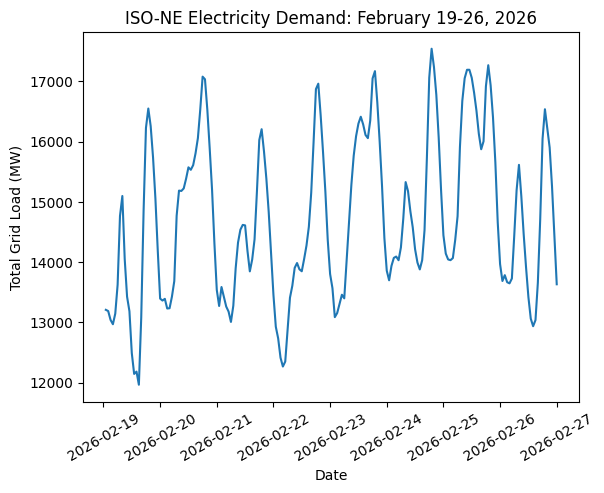

In [11]:
#For the project graphs, matplotlib allows for creation of graph to visualize my findings.
import matplotlib.pyplot as plots

plots.plot(load_data["Timestamp"], load_data["Total Load"])
plots.xticks(rotation=30)
plots.title("ISO-NE Electricity Demand: February 19-26, 2026")
plots.xlabel("Date")
plots.ylabel("Total Grid Load (MW)")
plots.show()

In [12]:
#Find the average of each day by grouping all load hourly results by date and taking the mean of them.
daily_average = load_data.groupby("Date")["Total Load"].mean()

daily_average

,Total Load
Date,
2026-02-19,13908.865417
2026-02-20,15031.095417
2026-02-21,14270.631250
2026-02-22,14237.104583
2026-02-23,15151.423333
2026-02-24,14975.518333
2026-02-25,15817.977917
2026-02-26,14419.171250


In [13]:
#Finding the total load demand % change of the day befroe the storm to the mian storm day
percent_change = (15151.423333 - 14237.104583)/14237.104583 * 100
percent_change

6.422083540018063

In [14]:
round(percent_change,2)

6.42

In [15]:
#Create a obervational period variables for total demand load variable
pre_storm = daily_average.loc["2026-02-19": "2026-02-22" ]
pre_storm

,Total Load
Date,
2026-02-19,13908.865417
2026-02-20,15031.095417
2026-02-21,14270.631250
2026-02-22,14237.104583


In [16]:
pre_storm_avg = pre_storm.mean()
pre_storm_avg

np.float64(14361.924166666666)

In [17]:
storm_day_avg = daily_average.loc["2026-02-23"]
storm_day_avg

np.float64(15151.423333333332)

In [18]:
storm_change = (storm_day_avg - pre_storm_avg)/pre_storm_avg* 100
print(round(storm_change, 2), "%")

5.5 %


In [19]:
peak_load = load_data.groupby("Date")["Total Load"].max()
peak_load

,Total Load
Date,
2026-02-19,16548.92
2026-02-20,17078.34
2026-02-21,16205.56
2026-02-22,16961.50
2026-02-23,17170.04
2026-02-24,17541.69
2026-02-25,17268.09
2026-02-26,16537.16


In [20]:
#Weather data manually implemented from NOAA
weather_data = {"Date":["2026-02-19", "2026-02-20", "2026-02-21", "2026-02-22", "2026-02-23", "2026-02-24", "2026-02-25", "2026-02-26",], "High Temp": [37, 36, 33, 35, 34, 33, 39, 43], "Low Temp": [30, 29, 28, 29, 23, 22, 17, 30] }

In [21]:
weather_data = pd.DataFrame(weather_data)

weather_data

,Date,High Temp,Low Temp
0,2026-02-19,37,30
1,2026-02-20,36,29
2,2026-02-21,33,28
3,2026-02-22,35,29
4,2026-02-23,34,23
5,2026-02-24,33,22
6,2026-02-25,39,17
7,2026-02-26,43,30


In [22]:
weather_data["Date"] = pd.to_datetime(weather_data["Date"])

In [23]:
weather_data["Bradley High"] = [40, 34, 40, 34, 32, 28, 38, 43]
weather_data["Bradley Low"] = [30, 27, 29, 29, 27, 12, 10, 22]

weather_data["Concord High"] = [43, 38, 32, 34, 30, 30, 33, 38]
weather_data["Concord Low"] = [11, 29, 18, 15, 22, 8, 3, 9]

weather_data["Portland High"] = [41, 35, 33, 32, 30, 32, 31, 38]
weather_data["Portland Low"] = [18, 16, 15, 10, 19, 13, 7, 15]

weather_data

,Date,High Temp,Low Temp,Bradley High,Bradley Low,Concord High,Concord Low,Portland High,Portland Low
0,2026-02-19,37,30,40,30,43,11,41,18
1,2026-02-20,36,29,34,27,38,29,35,16
2,2026-02-21,33,28,40,29,32,18,33,15
3,2026-02-22,35,29,34,29,34,15,32,10
4,2026-02-23,34,23,32,27,30,22,30,19
5,2026-02-24,33,22,28,12,30,8,32,13
6,2026-02-25,39,17,38,10,33,3,31,7
7,2026-02-26,43,30,43,22,38,9,38,15


In [24]:
weather_data = weather_data.rename(columns={
    "High Temp": "Boston High",
    "Low Temp": "Boston Low"
})

weather_data

,Date,Boston High,Boston Low,Bradley High,Bradley Low,Concord High,Concord Low,Portland High,Portland Low
0,2026-02-19,37,30,40,30,43,11,41,18
1,2026-02-20,36,29,34,27,38,29,35,16
2,2026-02-21,33,28,40,29,32,18,33,15
3,2026-02-22,35,29,34,29,34,15,32,10
4,2026-02-23,34,23,32,27,30,22,30,19
5,2026-02-24,33,22,28,12,30,8,32,13
6,2026-02-25,39,17,38,10,33,3,31,7
7,2026-02-26,43,30,43,22,38,9,38,15


In [25]:
#Table of all temperaturew data collected from the 4 New England airports.
weather_data["Regional High"] = (
    weather_data["Boston High"] +
    weather_data["Bradley High"] +
    weather_data["Concord High"] +
    weather_data["Portland High"]
) / 4

weather_data["Regional Low"] = (
    weather_data["Boston Low"] +
    weather_data["Bradley Low"] +
    weather_data["Concord Low"] +
    weather_data["Portland Low"]
) / 4

weather_data

,Date,Boston High,Boston Low,Bradley High,Bradley Low,Concord High,Concord Low,Portland High,Portland Low,Regional High,Regional Low
0,2026-02-19,37,30,40,30,43,11,41,18,40.25,22.25
1,2026-02-20,36,29,34,27,38,29,35,16,35.75,25.25
2,2026-02-21,33,28,40,29,32,18,33,15,34.50,22.50
3,2026-02-22,35,29,34,29,34,15,32,10,33.75,20.75
4,2026-02-23,34,23,32,27,30,22,30,19,31.50,22.75
5,2026-02-24,33,22,28,12,30,8,32,13,30.75,13.75
6,2026-02-25,39,17,38,10,33,3,31,7,35.25,9.25
7,2026-02-26,43,30,43,22,38,9,38,15,40.50,19.00


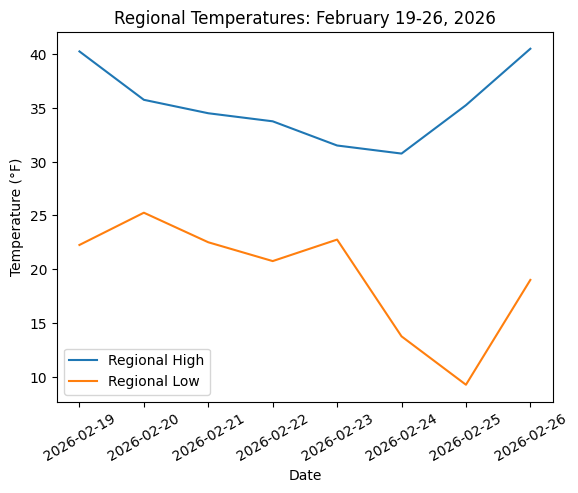

In [26]:
plots.plot(weather_data["Date"], weather_data["Regional High"], label="Regional High")
plots.plot(weather_data["Date"], weather_data["Regional Low"], label="Regional Low")

plots.title("Regional Temperatures: February 19-26, 2026")
plots.xlabel("Date")
plots.ylabel("Temperature (°F)")
plots.xticks(rotation=30)
plots.legend()
plots.show()

In [27]:
day_ahead = pd.read_csv(
    project_folder + "WW_DALMP_ISO_20260219.csv",
    skiprows=[0, 1, 2, 3, 5]
)

day_ahead.head()

,H,Date,Hour Ending,Location ID,Location Name,Location Type,Locational Marginal Price,Energy Component,Congestion Component,Marginal Loss Component
0,D,02/19/2026,1.0,321.0,UN.FRNKLNSQ13.810CC,NETWORK NODE,55.14,54.52,0.0,0.62
1,D,02/19/2026,1.0,322.0,UN.FRNKLNSQ13.811CC,NETWORK NODE,55.14,54.52,0.0,0.62
2,D,02/19/2026,1.0,323.0,UN.FRNKLNSQ13.89CC,NETWORK NODE,55.14,54.52,0.0,0.62
3,D,02/19/2026,1.0,326.0,UN.ALTRESCO13.8ALTR,NETWORK NODE,52.88,54.52,0.0,-1.64
4,D,02/19/2026,1.0,327.0,UN.EDDY 34.5AMOS,NETWORK NODE,54.81,54.52,0.0,0.29


In [28]:
#Only using data from the Internal Hub location (for variety).
NE_day_ahead = day_ahead[day_ahead["Location Name"] == ".H.INTERNAL_HUB"]
NE_day_ahead

,H,Date,Hour Ending,Location ID,Location Name,Location Type,Locational Marginal Price,Energy Component,Congestion Component,Marginal Loss Component
191,D,02/19/2026,1.0,4000.0,.H.INTERNAL_HUB,HUB,55.01,54.52,0.00,0.49
1406,D,02/19/2026,2.0,4000.0,.H.INTERNAL_HUB,HUB,58.09,57.58,0.00,0.51
2621,D,02/19/2026,3.0,4000.0,.H.INTERNAL_HUB,HUB,57.51,56.99,0.00,0.52
3836,D,02/19/2026,4.0,4000.0,.H.INTERNAL_HUB,HUB,54.75,54.29,0.00,0.46
5051,D,02/19/2026,5.0,4000.0,.H.INTERNAL_HUB,HUB,53.92,53.48,0.00,0.44
6266,D,02/19/2026,6.0,4000.0,.H.INTERNAL_HUB,HUB,61.65,61.18,0.00,0.47
7481,D,02/19/2026,7.0,4000.0,.H.INTERNAL_HUB,HUB,93.24,92.26,0.17,0.81
8696,D,02/19/2026,8.0,4000.0,.H.INTERNAL_HUB,HUB,99.48,98.39,0.31,0.78
9911,D,02/19/2026,9.0,4000.0,.H.INTERNAL_HUB,HUB,86.18,85.36,0.03,0.79
11126,D,02/19/2026,10.0,4000.0,.H.INTERNAL_HUB,HUB,66.52,65.90,0.00,0.62


In [29]:
NE_day_ahead.shape

(24, 10)

In [30]:
day_ahead_20 = pd.read_csv(
    project_folder + "WW_DALMP_ISO_20260220.csv",
    skiprows=[0, 1, 2, 3, 5]
)

day_ahead_20.head()

,H,Date,Hour Ending,Location ID,Location Name,Location Type,Locational Marginal Price,Energy Component,Congestion Component,Marginal Loss Component
0,D,02/20/2026,1.0,321.0,UN.FRNKLNSQ13.810CC,NETWORK NODE,62.63,62.16,0.0,0.47
1,D,02/20/2026,1.0,322.0,UN.FRNKLNSQ13.811CC,NETWORK NODE,62.63,62.16,0.0,0.47
2,D,02/20/2026,1.0,323.0,UN.FRNKLNSQ13.89CC,NETWORK NODE,62.63,62.16,0.0,0.47
3,D,02/20/2026,1.0,326.0,UN.ALTRESCO13.8ALTR,NETWORK NODE,60.70,62.16,0.0,-1.46
4,D,02/20/2026,1.0,327.0,UN.EDDY 34.5AMOS,NETWORK NODE,62.56,62.16,0.0,0.40


In [31]:
day_ahead_21 = pd.read_csv(
    project_folder + "WW_DALMP_ISO_20260221.csv",
    skiprows=[0, 1, 2, 3, 5]
)

day_ahead_22 = pd.read_csv(
    project_folder +
    "WW_DALMP_ISO_20260222.csv",
    skiprows=[0, 1, 2, 3, 5]
)

day_ahead_23 = pd.read_csv(
    project_folder + "WW_DALMP_ISO_20260223.csv",
    skiprows=[0, 1, 2, 3, 5]
)

day_ahead_24 = pd.read_csv(
   project_folder + "WW_DALMP_ISO_20260224.csv",
    skiprows=[0, 1, 2, 3, 5]
)

day_ahead_25 = pd.read_csv(
    project_folder + "WW_DALMP_ISO_20260225.csv",
    skiprows=[0, 1, 2, 3, 5]
)

day_ahead_26 = pd.read_csv(
    project_folder + "WW_DALMP_ISO_20260226.csv",
    skiprows=[0, 1, 2, 3, 5]
)

In [32]:
all_day_ahead = pd.concat([
    day_ahead,
    day_ahead_20,
    day_ahead_21,
    day_ahead_22,
    day_ahead_23,
    day_ahead_24,
    day_ahead_25,
    day_ahead_26
])

all_day_ahead.shape

(233288, 10)

In [33]:
NE_day_ahead = all_day_ahead[
    all_day_ahead["Location Name"] == ".H.INTERNAL_HUB"
].copy()

NE_day_ahead.shape

(192, 10)

In [34]:
NE_day_ahead["DATE"] = pd.to_datetime(NE_day_ahead["Date"])
NE_day_ahead.dtypes

,0
H,object
Date,object
Hour Ending,float64
Location ID,float64
Location Name,object
Location Type,object
Locational Marginal Price,float64
Energy Component,float64
Congestion Component,float64
Marginal Loss Component,float64


In [35]:
NE_day_ahead = NE_day_ahead.drop(columns=["DATE"])
NE_day_ahead["Date"] = pd.to_datetime(NE_day_ahead["Date"])
NE_day_ahead.dtypes

,0
H,object
Date,datetime64[ns]
Hour Ending,float64
Location ID,float64
Location Name,object
Location Type,object
Locational Marginal Price,float64
Energy Component,float64
Congestion Component,float64
Marginal Loss Component,float64


In [36]:
NE_day_ahead.groupby("Date")["Locational Marginal Price"].mean()

,Locational Marginal Price
Date,
2026-02-19,75.899583
2026-02-20,68.829583
2026-02-21,59.995000
2026-02-22,60.246250
2026-02-23,79.522917
2026-02-24,79.846250
2026-02-25,87.550833
2026-02-26,64.455417


In [37]:
daily_DA_price = NE_day_ahead.groupby("Date")["Locational Marginal Price"].mean()

daily_DA_price



,Locational Marginal Price
Date,
2026-02-19,75.899583
2026-02-20,68.829583
2026-02-21,59.995000
2026-02-22,60.246250
2026-02-23,79.522917
2026-02-24,79.846250
2026-02-25,87.550833
2026-02-26,64.455417


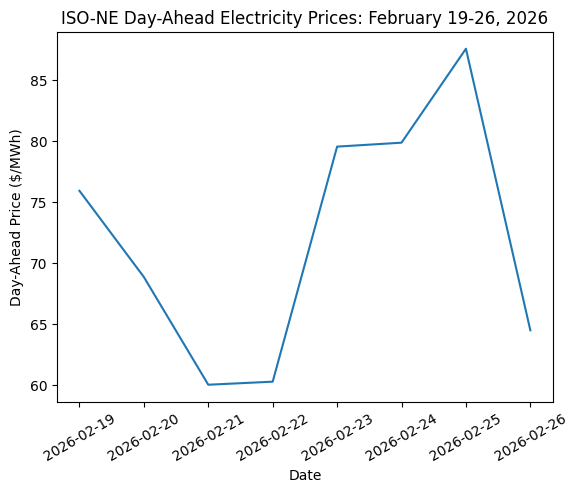

In [38]:
plots.plot(daily_DA_price.index, daily_DA_price)

plots.title("ISO-NE Day-Ahead Electricity Prices: February 19-26, 2026")
plots.xlabel("Date")
plots.ylabel("Day-Ahead Price ($/MWh)")
plots.xticks(rotation=30)
plots.show()

In [39]:
real_time_19 = pd.read_csv(
    project_folder + "lmp_rt_final_20260219.csv",
    skiprows =[0,1,2,3,5]
)
real_time_19.head()

,H,Date,Hour Ending,Location ID,Location Name,Location Type,Locational Marginal Price,Energy Component,Congestion Component,Marginal Loss Component
0,D,02/19/2026,1.0,321.0,UN.FRNKLNSQ13.810CC,NETWORK NODE,52.34,51.66,0.01,0.67
1,D,02/19/2026,1.0,322.0,UN.FRNKLNSQ13.811CC,NETWORK NODE,52.34,51.66,0.01,0.67
2,D,02/19/2026,1.0,323.0,UN.FRNKLNSQ13.89CC,NETWORK NODE,52.34,51.66,0.01,0.67
3,D,02/19/2026,1.0,326.0,UN.ALTRESCO13.8ALTR,NETWORK NODE,50.24,51.66,0.02,-1.44
4,D,02/19/2026,1.0,327.0,UN.EDDY 34.5AMOS,NETWORK NODE,51.93,51.66,0.01,0.26


In [40]:
real_time_20 = pd.read_csv(
    project_folder + "lmp_rt_final_20260220.csv",
    skiprows=[0, 1, 2, 3, 5]
)

real_time_21 = pd.read_csv(
    project_folder + "lmp_rt_final_20260221.csv",
    skiprows=[0, 1, 2, 3, 5]
)

real_time_22 = pd.read_csv(
    project_folder + "lmp_rt_final_20260222.csv",
    skiprows=[0, 1, 2, 3, 5]
)

real_time_23 = pd.read_csv(
    project_folder + "lmp_rt_final_20260223.csv",
    skiprows=[0, 1, 2, 3, 5]
)

real_time_24 = pd.read_csv(
    project_folder + "lmp_rt_final_20260224.csv",
    skiprows=[0, 1, 2, 3, 5]
)

real_time_25 = pd.read_csv(
    project_folder + "lmp_rt_final_20260225.csv",
    skiprows=[0, 1, 2, 3, 5]
)

real_time_26 = pd.read_csv(
    project_folder + "lmp_rt_final_20260226.csv",
    skiprows=[0, 1, 2, 3, 5]
)

In [41]:
all_real_time = pd.concat([
    real_time_19,
    real_time_20,
    real_time_21,
    real_time_22,
    real_time_23,
    real_time_24,
    real_time_25,
    real_time_26
])

all_real_time.shape

(233288, 10)

In [42]:
NE_real_time = all_real_time[
    all_real_time["Location Name"] == ".H.INTERNAL_HUB"
].copy()

NE_real_time.shape

(192, 10)

In [43]:
NE_real_time["Date"] = pd.to_datetime(NE_real_time["Date"])

daily_RT_price = NE_real_time.groupby("Date")["Locational Marginal Price"].mean()

daily_RT_price

,Locational Marginal Price
Date,
2026-02-19,58.339167
2026-02-20,59.892917
2026-02-21,61.760417
2026-02-22,56.710417
2026-02-23,69.076250
2026-02-24,91.046250
2026-02-25,89.549583
2026-02-26,63.718750


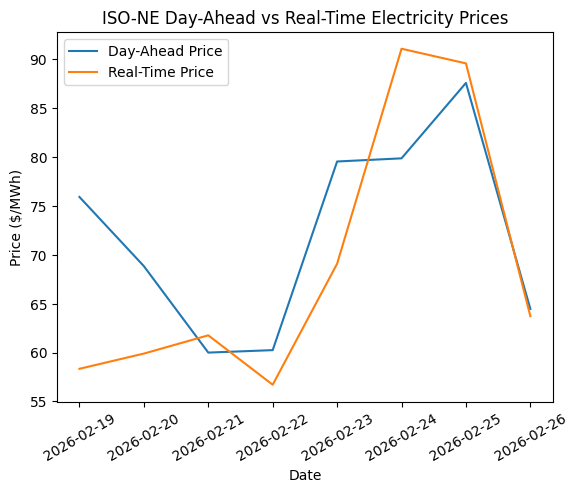

In [44]:
plots.figure()

plots.plot(pd.to_datetime(daily_DA_price.index), daily_DA_price, label="Day-Ahead Price")
plots.plot(pd.to_datetime(daily_RT_price.index), daily_RT_price, label="Real-Time Price")

plots.title("ISO-NE Day-Ahead vs Real-Time Electricity Prices")
plots.xlabel("Date")
plots.ylabel("Price ($/MWh)")
plots.xticks(rotation=30)
plots.legend()
plots.show()

In [45]:
forecast_19 = pd.read_csv(
    project_folder + "threedayreliabilityregionloadforecastreport_20260219.csv",
    skiprows=[0, 1, 2, 3, 5]
)

forecast_19.head()

,H,Forecast Date,Hour,Reliability Region,MW,%,Published Date
0,D,02/19/2026,1.0,.Z.CONNECTICUT,2934.665,23.089,02/18/2026 09:31:05
1,D,02/19/2026,1.0,.Z.CONNECTICUT,2934.665,23.089,02/18/2026 09:25:08
2,D,02/19/2026,1.0,.Z.CONNECTICUT,2920.645,23.180,02/18/2026 05:43:47
3,D,02/19/2026,1.0,.Z.CONNECTICUT,2920.645,23.180,02/18/2026 04:18:00
4,D,02/19/2026,1.0,.Z.CONNECTICUT,2860.000,23.214,02/17/2026 10:32:24


In [46]:
forecast_19["Reliability Region"].unique()

array(['.Z.CONNECTICUT', '.Z.MAINE', '.Z.NEMASSBOST', '.Z.NEWHAMPSHIRE',
       '.Z.RHODEISLAND', '.Z.SEMASS', '.Z.VERMONT', '.Z.WCMASS', nan],
      dtype=object)

In [47]:
forecast_19["Published Date"].unique()


array(['02/18/2026 09:31:05', '02/18/2026 09:25:08',
       '02/18/2026 05:43:47', '02/18/2026 04:18:00',
       '02/17/2026 10:32:24', '02/17/2026 09:11:52',
       '02/17/2026 04:14:41', '02/19/2026 04:23:58',
       '02/19/2026 08:16:33', '02/19/2026 09:28:11',
       '02/19/2026 13:46:31', nan], dtype=object)

In [48]:
#Use the latest forecast published on the day before the forecast date. (2/18 9:31 data is best estimate for 2/19. the 2/19 data will be affected by real time observation
# Filter to one published forecast
forecast_19_latest = forecast_19[
    forecast_19["Published Date"] == "02/18/2026 09:31:05"
]

# Add the 8 regions together for each hour
forecast_19_hourly = forecast_19_latest.groupby("Hour")["MW"].sum()
forecast_19_hourly

,MW
Hour,
1.0,12709.999
2.0,12450.001
3.0,12380.000
4.0,12519.999
5.0,12899.999
6.0,13810.000
7.0,15060.000
8.0,15550.001
9.0,15090.001


In [49]:
forecast_20 = pd.read_csv(
    project_folder + "threedayreliabilityregionloadforecastreport_20260220.csv",
    skiprows=[0, 1, 2, 3, 5]
)

forecast_20.head()

,H,Forecast Date,Hour,Reliability Region,MW,%,Published Date
0,D,02/20/2026,1.0,.Z.CONNECTICUT,2938.753,23.067,02/19/2026 13:46:31
1,D,02/20/2026,1.0,.Z.CONNECTICUT,2938.753,23.067,02/19/2026 09:28:11
2,D,02/20/2026,1.0,.Z.CONNECTICUT,2963.691,23.154,02/19/2026 08:16:33
3,D,02/20/2026,1.0,.Z.CONNECTICUT,2963.691,23.154,02/19/2026 04:23:58
4,D,02/20/2026,1.0,.Z.CONNECTICUT,2919.283,22.968,02/18/2026 09:31:06


In [50]:
#Using 2/19/26 hour 13 data to represent 2/20.
forecast_20_latest = forecast_20[
    forecast_20["Published Date"] == "02/19/2026 13:46:31"
]

forecast_20_latest.shape

(192, 7)

In [51]:
forecast_20_hourly = forecast_20_latest.groupby("Hour")["MW"].sum()

forecast_20_hourly

,MW
Hour,
1.0,12740.000
2.0,12310.000
3.0,12160.001
4.0,12140.000
5.0,12570.001
6.0,13470.001
7.0,14760.000
8.0,15450.000
9.0,15530.001


In [52]:
forecast_21 = pd.read_csv(
    project_folder + "threedayreliabilityregionloadforecastreport_20260221.csv",
    skiprows=[0, 1, 2, 3, 5]
)

forecast_22 = pd.read_csv(
    project_folder + "threedayreliabilityregionloadforecastreport_20260222.csv",
    skiprows=[0, 1, 2, 3, 5]
)

forecast_23 = pd.read_csv(
    project_folder + "threedayreliabilityregionloadforecastreport_20260223.csv",
    skiprows=[0, 1, 2, 3, 5]
)

forecast_24 = pd.read_csv(
    project_folder + "threedayreliabilityregionloadforecastreport_20260224.csv",
    skiprows=[0, 1, 2, 3, 5]
)

forecast_25 = pd.read_csv(
    project_folder + "threedayreliabilityregionloadforecastreport_20260225.csv",
    skiprows=[0, 1, 2, 3, 5]
)

forecast_26 = pd.read_csv(
    project_folder + "threedayreliabilityregionloadforecastreport_20260226.csv",
    skiprows=[0, 1, 2, 3, 5]
)

In [53]:
#Using 2/20 hour 20:49:18 data to represent 2/21.
forecast_21_latest = forecast_21[
    forecast_21["Published Date"] == "02/20/2026 20:49:18"
]

forecast_21_latest.shape

(192, 7)

In [54]:
forecast_21_hourly = forecast_21_latest.groupby("Hour")["MW"].sum()

forecast_21_hourly

,MW
Hour,
1.0,12420.000
2.0,12030.000
3.0,11790.001
4.0,11730.001
5.0,11890.000
6.0,12360.000
7.0,12910.002
8.0,13560.000
9.0,14020.000


In [55]:
#Using 2/21 hour 11:29:22 data to represent 2/22
forecast_22_latest = forecast_22[
    forecast_22["Published Date"] == "02/21/2026 11:29:22"
]

forecast_22_latest.shape

(192, 7)

In [56]:
all_forecasts = pd.concat([
    forecast_19,
    forecast_20,
    forecast_21,
    forecast_22,
    forecast_23,
    forecast_24,
    forecast_25,
    forecast_26
])

In [57]:
selected_forecasts = [
    "02/18/2026 09:31:05",
    "02/19/2026 13:46:31",
    "02/20/2026 20:49:18",
    "02/21/2026 11:29:22",
    "02/22/2026 17:46:16",
    "02/23/2026 19:22:17",
    "02/24/2026 09:29:31",
    "02/25/2026 21:21:42"
]

In [58]:
selected_forecast_data = all_forecasts[
    all_forecasts["Published Date"].isin(selected_forecasts)
]

selected_forecast_data.shape

(2744, 7)

In [59]:
#Repeat process for remaining 4 days
forecast_23_latest = forecast_23[
    forecast_23["Published Date"] == "02/22/2026 17:46:16"
]

forecast_24_latest = forecast_24[
    forecast_24["Published Date"] == "02/23/2026 19:22:17"
]

forecast_25_latest = forecast_25[
    forecast_25["Published Date"] == "02/24/2026 09:29:31"
]

forecast_26_latest = forecast_26[
    forecast_26["Published Date"] == "02/25/2026 21:21:42"
]

In [60]:
latest_forecasts = pd.concat([
    forecast_19_latest,
    forecast_20_latest,
    forecast_21_latest,
    forecast_22_latest,
    forecast_23_latest,
    forecast_24_latest,
    forecast_25_latest,
    forecast_26_latest
])

latest_forecasts.shape

(1536, 7)

In [61]:
forecast_hourly = latest_forecasts.groupby(
    ["Forecast Date", "Hour"]
)["MW"].sum()

forecast_hourly


Forecast Date  Hour
02/19/2026     1.0     12709.999
               2.0     12450.001
               3.0     12380.000
               4.0     12519.999
               5.0     12899.999
                         ...    
02/26/2026     20.0    16409.999
               21.0    15910.001
               22.0    15300.000
               23.0    14400.000
               24.0    13620.001
Name: MW, Length: 192, dtype: float64

In [62]:
daily_forecast = forecast_hourly.groupby("Forecast Date").mean()

daily_forecast

,MW
Forecast Date,
02/19/2026,14027.500333
02/20/2026,14490.000417
02/21/2026,13569.167000
02/22/2026,14025.833625
02/23/2026,15470.000167
02/24/2026,15702.083542
02/25/2026,15202.917125
02/26/2026,13893.333875


In [63]:
print("Actual Demand")
print(daily_average)

print("Forecast Demand")
print(daily_forecast)

Actual Demand
Date
2026-02-19    13908.865417
2026-02-20    15031.095417
2026-02-21    14270.631250
2026-02-22    14237.104583
2026-02-23    15151.423333
2026-02-24    14975.518333
2026-02-25    15817.977917
2026-02-26    14419.171250
Name: Total Load, dtype: float64
Forecast Demand
Forecast Date
02/19/2026    14027.500333
02/20/2026    14490.000417
02/21/2026    13569.167000
02/22/2026    14025.833625
02/23/2026    15470.000167
02/24/2026    15702.083542
02/25/2026    15202.917125
02/26/2026    13893.333875
Name: MW, dtype: float64


In [64]:
daily_forecast.index = pd.to_datetime(daily_forecast.index)

In [65]:
forecast_error = daily_average - daily_forecast

forecast_error

,0
Date,
2026-02-19,-118.634917
2026-02-20,541.095000
2026-02-21,701.464250
2026-02-22,211.270958
2026-02-23,-318.576833
2026-02-24,-726.565208
2026-02-25,615.060792
2026-02-26,525.837375


In [66]:
forecast_error_percent = (forecast_error / daily_forecast) * 100

forecast_error_percent.round(2)


,0
Date,
2026-02-19,-0.85
2026-02-20,3.73
2026-02-21,5.17
2026-02-22,1.51
2026-02-23,-2.06
2026-02-24,-4.63
2026-02-25,4.05
2026-02-26,3.78


In [67]:
price_difference = daily_RT_price - daily_DA_price

price_difference.round(2)

,Locational Marginal Price
Date,
2026-02-19,-17.56
2026-02-20,-8.94
2026-02-21,1.77
2026-02-22,-3.54
2026-02-23,-10.45
2026-02-24,11.20
2026-02-25,2.00
2026-02-26,-0.74


In [68]:
#Summarize Case Study #1 findings in a grand table.
summary = pd.DataFrame({
    "Actual Demand": daily_average,
    "Forecast Demand": daily_forecast,
    "Forecast Error %": forecast_error_percent,
    "Day-Ahead Price": daily_DA_price,
    "Real-Time Price": daily_RT_price,
    "RT - DA": price_difference
})

summary.round(2)

,Actual Demand,Forecast Demand,Forecast Error %,Day-Ahead Price,Real-Time Price,RT - DA
2026-02-19,13908.87,14027.50,-0.85,75.90,58.34,-17.56
2026-02-20,15031.10,14490.00,3.73,68.83,59.89,-8.94
2026-02-21,14270.63,13569.17,5.17,60.00,61.76,1.77
2026-02-22,14237.10,14025.83,1.51,60.25,56.71,-3.54
2026-02-23,15151.42,15470.00,-2.06,79.52,69.08,-10.45
2026-02-24,14975.52,15702.08,-4.63,79.85,91.05,11.20
2026-02-25,15817.98,15202.92,4.05,87.55,89.55,2.00
2026-02-26,14419.17,13893.33,3.78,64.46,63.72,-0.74


In [69]:
summary["Regional High"] = weather_data["Regional High"].values
summary["Regional Low"] = weather_data["Regional Low"].values
summary.round(2)

,Actual Demand,Forecast Demand,Forecast Error %,Day-Ahead Price,Real-Time Price,RT - DA,Regional High,Regional Low
2026-02-19,13908.87,14027.50,-0.85,75.90,58.34,-17.56,40.25,22.25
2026-02-20,15031.10,14490.00,3.73,68.83,59.89,-8.94,35.75,25.25
2026-02-21,14270.63,13569.17,5.17,60.00,61.76,1.77,34.50,22.50
2026-02-22,14237.10,14025.83,1.51,60.25,56.71,-3.54,33.75,20.75
2026-02-23,15151.42,15470.00,-2.06,79.52,69.08,-10.45,31.50,22.75
2026-02-24,14975.52,15702.08,-4.63,79.85,91.05,11.20,30.75,13.75
2026-02-25,15817.98,15202.92,4.05,87.55,89.55,2.00,35.25,9.25
2026-02-26,14419.17,13893.33,3.78,64.46,63.72,-0.74,40.50,19.00


#Case Study #1 Findings - Blizzard of 2026

The Northeastern U.S. winter storm of February 22–24, 2026, better known as the Blizzard of 2026, which crippled coastal and inland southern New England with nearly 38 inches of snow in parts of Rhode Island, extreme winds, coastal flooding, and relentless whiteout conditions, was associated with notable changes in ISO-NE electricity demand and wholesale power prices.

Average system demand increased from 14,237 MW on February 22 to 15,151 MW on February 23, the main storm day. However, actual demand on February 23 was 2.06% below the previous-day forecast. On February 24, actual demand was 4.63% below forecast before moving 4.05% above forecast on February 25.

As the storm approached, Day-Ahead prices increased significantly. ISO-NE’s Internal Hub (a virtual hub composed of multiple pricing nodes within the ISO-NE system) increased from 60.25 USD/MWh on February 22 to 79.52 USD/MWh on February 23 and remained elevated at $79.85 USD/MWh on February 24.

Real-Time prices did not follow the same pattern. The Real-Time price averaged 69.08 USD/MWh on February 23, which was 10.45 USD/MWh below the Day-Ahead price. On February 24, however, the Real-Time price increased to 91.05 USD/MWh, 11.20 USD/MWh above the Day-Ahead price. Real-Time prices remained elevated at 89.55 USD/MWh on February 25 before falling to 63.72 USD/MWh on February 26.

This case study’s timing suggests that the largest effects on Real-Time prices did not occur during the main storm itself, but instead during the days following the storm, February 24 and 25. Regional temperatures also remained cold following the storm. The four-station average low fell to 13.75°F on February 24 and reached 9.25°F on February 25.

Preliminary findings suggest a market impact that extends beyond the main precipitation period of a MECS (Major East Coast Winter Storm). Temperature could potentially be a greater factor than precipitation itself, as a MECS—especially a nor’easter style storm is often followed by a post-storm cold shot that could contribute to higher electricity prices and demand. In this case, the coldest portion of the observation period occurred in the days following the storm, with the regional average low reaching 9.25°F on February 25. However, this case study alone cannot determine that temperature caused the price increases, since wholesale electricity prices can also be affected by fuel prices, generation availability, transmission constraints, imports, and other market conditions.

In [70]:
pre_storm_DA = daily_DA_price.loc["2026-02-19":"2026-02-22"].mean()
pre_storm_RT = daily_RT_price.loc["2026-02-19":"2026-02-22"].mean()

print(round(pre_storm_DA, 2))
print(round(pre_storm_RT, 2))

66.24
59.18


## Case Study 2: January 23–27, 2026 North American Winter Storm

### ISO-NE Analysis Window: January 21–29, 2026

Observation Period: January 21–29, 2026

This case study examines the major winter storm that affected much of the eastern United States between January 23–27, 2026. This storm presented a significantly different meteorological setup than the February storm examined in Case Study 1.

To start, an extremely cold Arctic air mass was already established ahead of the storm. Early model projections suggested that this cold air would suppress the storm farther south, potentially leaving New England on the northern edge of the system while producing significant winter weather across the Mid-Atlantic and southeastern United States.

As the storm approached, model projections began showing a slower progression of the system, with its main energy remaining farther west for longer. This allowed the strong Arctic high-pressure system to retreat toward northeastern Canada, reducing the suppression that had initially been expected to keep the storm farther south. The slower progression also created a more favorable setup for the storm to track farther north and affect New England more significantly.

The resulting storm was a long-duration event in which subtropical moisture interacted with an established Arctic air mass, producing heavy snowfall and substantial accumulations across parts of the Northeast.

This case study is particularly interesting because early forecasts suggested that New England could experience relatively limited impacts before later projections shifted the storm farther north. Unlike Case Study 1, extreme cold was already established before the storm arrived.

Therefore, this analysis will examine how ISO-NE electricity demand and wholesale power prices changed as weather forecasts evolved, particularly as the likelihood of significant snowfall increased while cold temperatures were already in place. Comparing Day-Ahead and Real-Time prices may help identify how market expectations differed from conditions experienced during and immediately after the storm.

In [71]:
jan_load_data = pd.read_csv(
    project_folder + "rt_hourlysysload_20260121_20260129.csv",
    skiprows=6,
    names=["Type", "Date", "Hour Ending", "Total Load"]
)

jan_load_data

,Type,Date,Hour Ending,Total Load
0,D,01/21/2026,1.0,15910.00
1,D,01/21/2026,2.0,15619.10
2,D,01/21/2026,3.0,15265.24
3,D,01/21/2026,4.0,15324.71
4,D,01/21/2026,5.0,15679.15
...,...,...,...,...
212,D,01/29/2026,21.0,18857.24
213,D,01/29/2026,22.0,18122.09
214,D,01/29/2026,23.0,17242.86
215,D,01/29/2026,24.0,16740.26


In [72]:
jan_load_data = jan_load_data[jan_load_data["Type"] == "D"].copy()

jan_load_data.shape


(216, 4)

In [73]:
jan_load_data["Date"] = pd.to_datetime(jan_load_data["Date"])
jan_load_data["Total Load"] = pd.to_numeric(jan_load_data["Total Load"])

jan_load_data.dtypes

,0
Type,object
Date,datetime64[ns]
Hour Ending,float64
Total Load,float64


In [74]:
jan_load_data["Timestamp"] = (
    jan_load_data["Date"] +
    pd.to_timedelta(jan_load_data["Hour Ending"], unit="h")
)

jan_load_data.head()

,Type,Date,Hour Ending,Total Load,Timestamp
0,D,2026-01-21,1.0,15910.00,2026-01-21 01:00:00
1,D,2026-01-21,2.0,15619.10,2026-01-21 02:00:00
2,D,2026-01-21,3.0,15265.24,2026-01-21 03:00:00
3,D,2026-01-21,4.0,15324.71,2026-01-21 04:00:00
4,D,2026-01-21,5.0,15679.15,2026-01-21 05:00:00


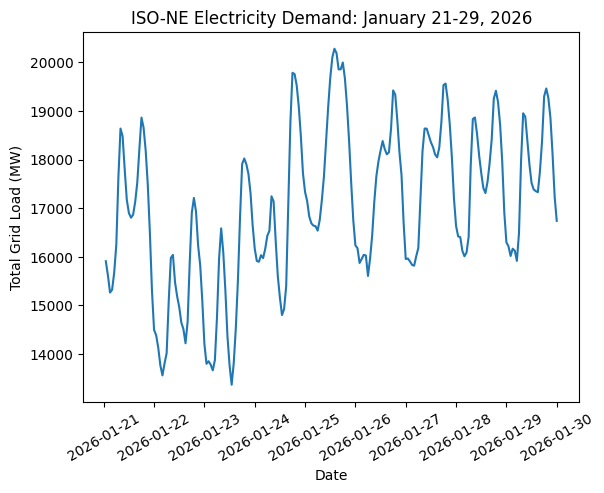

In [75]:
#MW measures power demand, while MWh measures energy consumed over time.
plots.plot(jan_load_data["Timestamp"], jan_load_data["Total Load"])

plots.title("ISO-NE Electricity Demand: January 21-29, 2026")
plots.xlabel("Date")
plots.ylabel("Total Grid Load (MW)")
plots.xticks(rotation=30)

plots.show()

In [76]:
jan_daily_average = jan_load_data.groupby("Date")["Total Load"].mean()

jan_daily_average.round(2)

,Total Load
Date,
2026-01-21,16947.27
2026-01-22,15115.71
2026-01-23,15482.42
2026-01-24,16961.69
2026-01-25,18212.19
2026-01-26,17356.68
2026-01-27,17731.26
2026-01-28,17656.99
2026-01-29,17656.45


In [77]:
#Show January peak demand and round toi 2 decimals
jan_peak_load = jan_load_data.groupby("Date")["Total Load"].max()

jan_peak_load.round(2)

,Total Load
Date,
2026-01-21,18863.52
2026-01-22,17211.22
2026-01-23,18022.45
2026-01-24,19784.26
2026-01-25,20279.46
2026-01-26,19422.48
2026-01-27,19563.01
2026-01-28,19415.34
2026-01-29,19461.78


In [78]:
#Manually add the NOAA weather data for the four New England locations and use pandas to create the table
jan_weather_data = pd.DataFrame({
    "Date": pd.date_range("2026-01-21", "2026-01-29"),

    "Boston High": [35, 46, 34, 15, 29, 29, 23, 23, 26],
    "Boston Low": [13, 33, 14, 5, 6, 14, 10, 12, 12],

    "Hartford High": [32, 44, 33, 13, 14, 21, 21, 22, 21],
    "Hartford Low": [0, 21, 10, 1, 4, 12, 1, 3, -1],

    "Concord High": [24, 41, 28, 10, 9, 19, 18, 20, 21],
    "Concord Low": [-6, 17, 8, -3, -1, 8, 1, -10, -11],

    "Portland High": [24, 41, 30, 12, 7, 15, 17, 22, 22],
    "Portland Low": [7, 23, 11, -3, -6, 6, 1, -2, 0]
})

jan_weather_data

,Date,Boston High,Boston Low,Hartford High,Hartford Low,Concord High,Concord Low,Portland High,Portland Low
0,2026-01-21,35,13,32,0,24,-6,24,7
1,2026-01-22,46,33,44,21,41,17,41,23
2,2026-01-23,34,14,33,10,28,8,30,11
3,2026-01-24,15,5,13,1,10,-3,12,-3
4,2026-01-25,29,6,14,4,9,-1,7,-6
5,2026-01-26,29,14,21,12,19,8,15,6
6,2026-01-27,23,10,21,1,18,1,17,1
7,2026-01-28,23,12,22,3,20,-10,22,-2
8,2026-01-29,26,12,21,-1,21,-11,22,0


In [79]:
#Create the regional highs and regional lows. Use axis to average across columns specifically for each day
jan_weather_data["Regional High"] = jan_weather_data[
    ["Boston High", "Hartford High", "Concord High", "Portland High"]
].mean(axis=1)

jan_weather_data["Regional Low"] = jan_weather_data[
    ["Boston Low", "Hartford Low", "Concord Low", "Portland Low"]
].mean(axis=1)

jan_weather_data[["Date", "Regional High", "Regional Low"]]

,Date,Regional High,Regional Low
0,2026-01-21,28.75,3.50
1,2026-01-22,43.00,23.50
2,2026-01-23,31.25,10.75
3,2026-01-24,12.50,0.00
4,2026-01-25,14.75,0.75
5,2026-01-26,21.00,10.00
6,2026-01-27,19.75,3.25
7,2026-01-28,21.75,0.75
8,2026-01-29,22.50,0.00


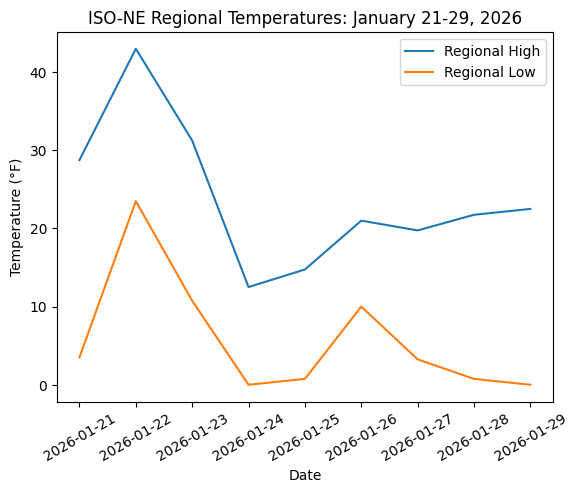

In [80]:
plots.plot(jan_weather_data["Date"], jan_weather_data["Regional High"], label="Regional High")
plots.plot(jan_weather_data["Date"], jan_weather_data["Regional Low"], label="Regional Low")

plots.title("ISO-NE Regional Temperatures: January 21-29, 2026")
plots.xlabel("Date")
plots.ylabel("Temperature (°F)")
plots.xticks(rotation=30)
plots.legend()
plots.show()

In [81]:
#Creating a Janaury file variable using glob will group all ISO-NE demand forecast files I downloaded
import glob

jan_forecast_files = sorted(glob.glob(
    project_folder + "threedayreliabilityregionloadforecastreport_202601*.csv"
))

jan_forecast_files

['/content/ISO-NE-Winter-Storm-Analysis/data/threedayreliabilityregionloadforecastreport_20260121.csv',
 '/content/ISO-NE-Winter-Storm-Analysis/data/threedayreliabilityregionloadforecastreport_20260122.csv',
 '/content/ISO-NE-Winter-Storm-Analysis/data/threedayreliabilityregionloadforecastreport_20260123.csv',
 '/content/ISO-NE-Winter-Storm-Analysis/data/threedayreliabilityregionloadforecastreport_20260124.csv',
 '/content/ISO-NE-Winter-Storm-Analysis/data/threedayreliabilityregionloadforecastreport_20260125.csv',
 '/content/ISO-NE-Winter-Storm-Analysis/data/threedayreliabilityregionloadforecastreport_20260126.csv',
 '/content/ISO-NE-Winter-Storm-Analysis/data/threedayreliabilityregionloadforecastreport_20260127.csv',
 '/content/ISO-NE-Winter-Storm-Analysis/data/threedayreliabilityregionloadforecastreport_20260128.csv',
 '/content/ISO-NE-Winter-Storm-Analysis/data/threedayreliabilityregionloadforecastreport_20260129.csv']

In [82]:
jan_forecast_sample = pd.read_csv(
    jan_forecast_files[0],
    skiprows=6,
    names=["Type", "Forecast Date", "Hour", "Reliability Region",
           "MW", "Percent", "Published Date"]
)

jan_forecast_sample.head(10)

,Type,Forecast Date,Hour,Reliability Region,MW,Percent,Published Date
0,D,01/21/2026,1.0,.Z.CONNECTICUT,3546.698,23.900,01/20/2026 09:28:45
1,D,01/21/2026,1.0,.Z.CONNECTICUT,3549.369,23.918,01/20/2026 04:17:34
2,D,01/21/2026,1.0,.Z.CONNECTICUT,3600.848,24.022,01/19/2026 09:28:43
3,D,01/21/2026,1.0,.Z.CONNECTICUT,3574.609,24.071,01/19/2026 04:21:07
4,D,01/21/2026,1.0,.Z.MAINE,1565.102,10.547,01/20/2026 09:28:45
5,D,01/21/2026,1.0,.Z.MAINE,1559.844,10.511,01/20/2026 04:17:34
6,D,01/21/2026,1.0,.Z.MAINE,1556.849,10.386,01/19/2026 09:28:43
7,D,01/21/2026,1.0,.Z.MAINE,1535.133,10.338,01/19/2026 04:21:07
8,D,01/21/2026,1.0,.Z.NEMASSBOST,3025.331,20.386,01/20/2026 09:28:45
9,D,01/21/2026,1.0,.Z.NEMASSBOST,3026.756,20.396,01/20/2026 04:17:34


In [83]:
jan_forecast_data = pd.concat(
    [
        pd.read_csv(
            file,
            skiprows=6,
            names=["Type", "Forecast Date", "Hour", "Reliability Region",
                   "MW", "Percent", "Published Date"]
        )
        for file in jan_forecast_files
    ],
    ignore_index=True
)

jan_forecast_data.shape

(14265, 7)

In [84]:
jan_forecast_data = jan_forecast_data[
    jan_forecast_data["Type"] == "D"
].copy()

jan_forecast_data.shape

(14256, 7)

In [85]:
jan_forecast_data["Forecast Date"] = pd.to_datetime(jan_forecast_data["Forecast Date"])
jan_forecast_data["Published Date"] = pd.to_datetime(jan_forecast_data["Published Date"])

jan_forecast_data["Hour"] = pd.to_numeric(jan_forecast_data["Hour"])
jan_forecast_data["MW"] = pd.to_numeric(jan_forecast_data["MW"])

jan_forecast_data.dtypes

,0
Type,object
Forecast Date,datetime64[ns]
Hour,float64
Reliability Region,object
MW,float64
Percent,float64
Published Date,datetime64[ns]


In [86]:
jan_forecast_21_latest = jan_forecast_data[
    jan_forecast_data["Published Date"] == pd.Timestamp("2026-01-20 09:28:45")
]

In [87]:
jan_forecast_21_latest = jan_forecast_21_latest[
    jan_forecast_21_latest["Forecast Date"] == "2026-01-21"
]

jan_forecast_21_latest.shape

(192, 7)

In [88]:
jan_forecast_21_hourly = jan_forecast_21_latest.groupby("Hour")["MW"].sum()

jan_forecast_21_hourly

,MW
Hour,
1.0,14840.001
2.0,14550.000
3.0,14320.000
4.0,14400.001
5.0,14749.999
6.0,15730.001
7.0,17209.999
8.0,18150.001
9.0,18160.001


In [89]:
#Calculate the average forecasted demand for January 21.
#This will be compared with actual demand to measure forecast error.
jan_forecast_21_avg = jan_forecast_21_hourly.mean()

jan_forecast_21_avg

np.float64(16556.250416666666)

In [90]:
#This is the Jan 22nd forecasted demand. we pick the data during the Jan 21st 9:30 Am runtime as it is the forecast for the following day Jan 22nd.
jan_forecast_data[
    jan_forecast_data["Forecast Date"] == "2026-01-22"
]["Published Date"].drop_duplicates().sort_values()

,Published Date
1036,2026-01-20 04:17:34
1035,2026-01-20 09:28:45
1034,2026-01-21 04:15:47
1033,2026-01-21 09:30:00
1193,2026-01-22 04:19:36
1393,2026-01-22 09:15:41
1441,2026-01-22 10:32:55
1553,2026-01-22 12:22:11


In [91]:
# I selected the January 22 demand forecast published on January 21 at 9:30 AM (day ahead)

jan_forecast_22_latest = jan_forecast_data[
    (jan_forecast_data["Forecast Date"] == "2026-01-22") &
    (jan_forecast_data["Published Date"] == "2026-01-21 09:30:00")
]

jan_forecast_22_latest.shape

(192, 7)

In [92]:
jan_forecast_22_latest.columns

Index(['Type', 'Forecast Date', 'Hour', 'Reliability Region', 'MW', 'Percent',
       'Published Date'],
      dtype='object')

In [93]:
# Show the 8 reliability regions included in the January 22 forecast

jan_forecast_22_latest["Reliability Region"].unique()

array(['.Z.CONNECTICUT', '.Z.MAINE', '.Z.NEMASSBOST', '.Z.NEWHAMPSHIRE',
       '.Z.RHODEISLAND', '.Z.SEMASS', '.Z.VERMONT', '.Z.WCMASS'],
      dtype=object)

In [94]:
# Add the 8 regional demand forecasts together for each hour
#Regions are CT, Maine, Ne Mass Boston, New hampshire, Rhode island, Se MAss, Vermont, MC MAss

jan_forecast_22_hourly = jan_forecast_22_latest.groupby("Hour")["MW"].sum()

jan_forecast_22_hourly

,MW
Hour,
1.0,13410.000
2.0,12890.001
3.0,12830.000
4.0,12780.000
5.0,13109.999
6.0,14070.001
7.0,15480.001
8.0,16450.000
9.0,16520.001


In [95]:
# I will calculate the average forecasted demand for January 22.
# This will then be compared with actual demand to measure forecast error.

jan_forecast_22_avg = jan_forecast_22_hourly.mean()

jan_forecast_22_avg

np.float64(15032.083625)

In [96]:
# This will calculate the difference % wise between the forecasted demand and the actual demand averages through the 24 hour day.
jan_forecast_22_error = (
    (jan_daily_average.loc["2026-01-22"] - jan_forecast_22_avg)
    / jan_forecast_22_avg
) * 100

jan_forecast_22_error

np.float64(0.5562970759928009)

In [97]:
# Finding publification times available for January 23's demand forecast

jan_forecast_data[
    jan_forecast_data["Forecast Date"] == "2026-01-23"
]["Published Date"].drop_duplicates().sort_values()

,Published Date
2263,2026-01-21 04:15:47
2262,2026-01-21 09:30:00
2261,2026-01-22 04:19:36
2260,2026-01-22 09:15:41
2259,2026-01-22 10:32:56
2258,2026-01-22 12:22:12
2498,2026-01-23 04:19:37
2778,2026-01-23 09:18:19
2842,2026-01-23 10:22:16
2986,2026-01-23 12:26:13


In [98]:
# Select the January 23 demand forecast published on January 22 12:22:12 (latest of the prior day forecast for Jan 23rd)

jan_forecast_23_latest = jan_forecast_data[
    (jan_forecast_data["Forecast Date"] == "2026-01-23") &
    (jan_forecast_data["Published Date"] == "2026-01-22 12:22:12")
]

jan_forecast_23_latest.shape

(192, 7)

In [99]:
# Adding the 8 regional demand forecasts together for each hour

jan_forecast_23_hourly = jan_forecast_23_latest.groupby("Hour")["MW"].sum()

jan_forecast_23_hourly

,MW
Hour,
1.0,13140.001
2.0,13000.000
3.0,12820.000
4.0,12880.001
5.0,13340.000
6.0,14280.002
7.0,15770.000
8.0,16560.000
9.0,16330.001


In [100]:
# Calculate the average forecasted demand for January 23.
# This will be compared with actual demand to measure forecast error.

jan_forecast_23_avg = jan_forecast_23_hourly.mean()

jan_forecast_23_avg

np.float64(15511.250625)

In [101]:
# Calculate how much actual demand difference from forecasted demand on January 23

jan_forecast_23_error = (
    (jan_daily_average.loc["2026-01-23"] - jan_forecast_23_avg)
    / jan_forecast_23_avg
) * 100

jan_forecast_23_error

np.float64(-0.18584225753450367)

In [102]:
# Select forecasts for January 24 through January 29
#The one by one processes was accurate, but time consuming. with AI help I was able to find a way to condence everything for 24-29
jan_remaining = jan_forecast_data[
    (jan_forecast_data["Forecast Date"] >= "2026-01-24") &
    (jan_forecast_data["Forecast Date"] <= "2026-01-29")
].copy()

# Keep only forecasts published the day before the operating date
jan_remaining = jan_remaining[
    jan_remaining["Published Date"].dt.normalize()
    == jan_remaining["Forecast Date"] - pd.Timedelta(days=1)
]

# Find the latest previous-day publication for each operating date
latest_publications = jan_remaining.groupby("Forecast Date")["Published Date"].transform("max")

jan_remaining = jan_remaining[
    jan_remaining["Published Date"] == latest_publications
]

# Sum the 8 regional forecasts for each hour
jan_remaining_hourly = jan_remaining.groupby(
    ["Forecast Date", "Hour"]
)["MW"].sum()

# Calculate average daily forecasted demand
jan_remaining_avg = jan_remaining_hourly.groupby("Forecast Date").mean()

# Compare forecasted demand with actual demand
jan_remaining_results = pd.DataFrame({
    "Forecasted Demand (MW)": jan_remaining_avg,
    "Actual Demand (MW)": jan_daily_average
})

jan_remaining_results["Forecast Error (%)"] = (
    (jan_remaining_results["Actual Demand (MW)"] -
     jan_remaining_results["Forecasted Demand (MW)"])
    / jan_remaining_results["Forecasted Demand (MW)"]
) * 100

jan_remaining_results.loc["2026-01-24":"2026-01-29"]

,Forecasted Demand (MW),Actual Demand (MW),Forecast Error (%)
2026-01-24,16334.167167,16961.690833,3.841786
2026-01-25,17202.083958,18212.193333,5.872017
2026-01-26,17366.667083,17356.683333,-0.057488
2026-01-27,17687.917208,17731.264167,0.245065
2026-01-28,17622.917083,17656.991250,0.193351
2026-01-29,17524.167042,17656.448333,0.754851


In [103]:
# Loading in the file which contains the real time vs. day ahead LMPs

jan_price_data = pd.read_csv(
    project_folder + "da_rt_lmp_4000_20260121_20260129.csv",
    skiprows=6
)

jan_price_data.head()

,H,Date,Hour Ending,Location ID,Location Name,Location Type,Locational Marginal Price,Energy Component,Congestion Component,Marginal Loss Component,Locational Marginal Price.1,Energy Component.1,Congestion Component.1,Marginal Loss Component.1
0,H,Date,HE,String,String,String,Number,Number,Number,Number,Number,Number,Number,Number
1,D,01/21/2026,01,4000,.H.INTERNAL_HUB,HUB,128.6,127.15,0.09,1.36,187.6,185.15,0.56,1.89
2,D,01/21/2026,02,4000,.H.INTERNAL_HUB,HUB,128.7,127.22,0.1,1.38,187.31,185.33,0.24,1.74
3,D,01/21/2026,03,4000,.H.INTERNAL_HUB,HUB,128.53,127.02,0.1,1.41,176.12,174.14,0.38,1.6
4,D,01/21/2026,04,4000,.H.INTERNAL_HUB,HUB,128.5,127.03,0.07,1.4,175.82,173.8,0.4,1.62


In [104]:
# Keep only the actual electricity price data rows

jan_price_data = jan_price_data[jan_price_data["H"] == "D"].copy()

jan_price_data.head()

,H,Date,Hour Ending,Location ID,Location Name,Location Type,Locational Marginal Price,Energy Component,Congestion Component,Marginal Loss Component,Locational Marginal Price.1,Energy Component.1,Congestion Component.1,Marginal Loss Component.1
1,D,01/21/2026,01,4000,.H.INTERNAL_HUB,HUB,128.6,127.15,0.09,1.36,187.6,185.15,0.56,1.89
2,D,01/21/2026,02,4000,.H.INTERNAL_HUB,HUB,128.7,127.22,0.1,1.38,187.31,185.33,0.24,1.74
3,D,01/21/2026,03,4000,.H.INTERNAL_HUB,HUB,128.53,127.02,0.1,1.41,176.12,174.14,0.38,1.6
4,D,01/21/2026,04,4000,.H.INTERNAL_HUB,HUB,128.5,127.03,0.07,1.4,175.82,173.8,0.4,1.62
5,D,01/21/2026,05,4000,.H.INTERNAL_HUB,HUB,129.38,128.03,0.06,1.29,186.88,184.59,0.57,1.72


In [105]:
# Convert Day-Ahead and Real-Time electricity prices to numeric values
#listyed as strings from original dataset

jan_price_data["Locational Marginal Price"] = pd.to_numeric(
    jan_price_data["Locational Marginal Price"]
)

jan_price_data["Locational Marginal Price.1"] = pd.to_numeric(
    jan_price_data["Locational Marginal Price.1"]
)

jan_price_data[["Date", "Hour Ending", "Locational Marginal Price", "Locational Marginal Price.1"]].head()

,Date,Hour Ending,Locational Marginal Price,Locational Marginal Price.1
1,01/21/2026,01,128.60,187.60
2,01/21/2026,02,128.70,187.31
3,01/21/2026,03,128.53,176.12
4,01/21/2026,04,128.50,175.82
5,01/21/2026,05,129.38,186.88


In [106]:
#Cleaning up the table by changing pricing label names.
jan_price_data = jan_price_data.rename(columns={
    "Locational Marginal Price": "Day-Ahead LMP",
    "Locational Marginal Price.1": "Real-Time LMP"
})

jan_price_data[["Date", "Hour Ending", "Day-Ahead LMP", "Real-Time LMP"]].head()


,Date,Hour Ending,Day-Ahead LMP,Real-Time LMP
1,01/21/2026,01,128.60,187.60
2,01/21/2026,02,128.70,187.31
3,01/21/2026,03,128.53,176.12
4,01/21/2026,04,128.50,175.82
5,01/21/2026,05,129.38,186.88


In [107]:
# Calculating average Day-Ahead and Real-Time electricity prices for each day.

jan_daily_prices = jan_price_data.groupby("Date")[
    ["Day-Ahead LMP", "Real-Time LMP"]
].mean()

jan_daily_prices

,Day-Ahead LMP,Real-Time LMP
Date,,
01/21/2026,134.317500,148.915000
01/22/2026,79.292500,95.620833
01/23/2026,122.962917,114.224167
01/24/2026,257.008750,323.182917
01/25/2026,433.956250,426.278750
01/26/2026,436.009583,365.450833
01/27/2026,639.141667,308.588750
01/28/2026,423.312083,224.894167
01/29/2026,346.809167,250.322917


In [108]:
# Calculate the difference between Real-Time and Day-Ahead electricity prices

jan_daily_prices["RT - DA Difference"] = (
    jan_daily_prices["Real-Time LMP"] -
    jan_daily_prices["Day-Ahead LMP"]
)

jan_daily_prices

,Day-Ahead LMP,Real-Time LMP,RT - DA Difference
Date,,,
01/21/2026,134.317500,148.915000,14.597500
01/22/2026,79.292500,95.620833,16.328333
01/23/2026,122.962917,114.224167,-8.738750
01/24/2026,257.008750,323.182917,66.174167
01/25/2026,433.956250,426.278750,-7.677500
01/26/2026,436.009583,365.450833,-70.558750
01/27/2026,639.141667,308.588750,-330.552917
01/28/2026,423.312083,224.894167,-198.417917
01/29/2026,346.809167,250.322917,-96.486250


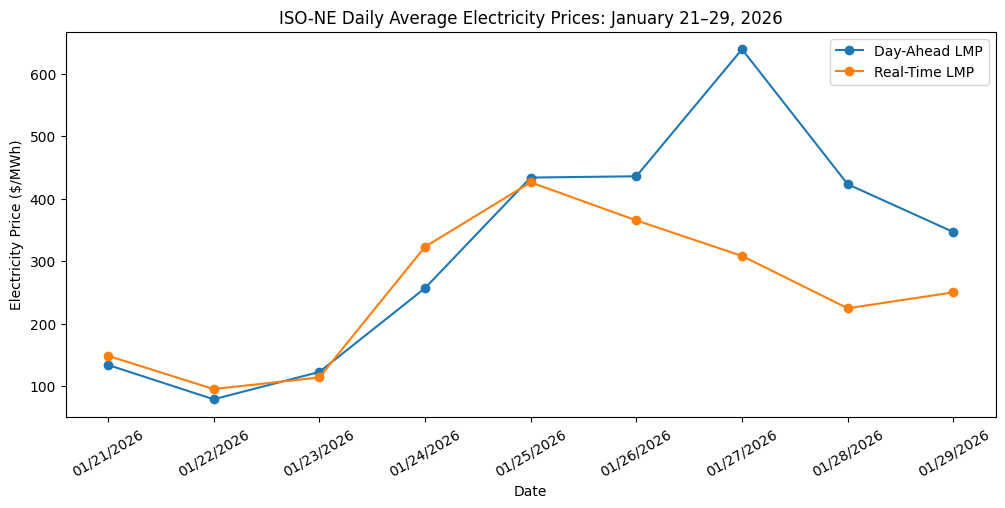

In [109]:
# Plot daily average Day-Ahead and Real-Time electricity prices

plots.figure(figsize=(12, 5))

plots.plot(jan_daily_prices.index, jan_daily_prices["Day-Ahead LMP"],
           marker="o", label="Day-Ahead LMP")

plots.plot(jan_daily_prices.index, jan_daily_prices["Real-Time LMP"],
           marker="o", label="Real-Time LMP")

plots.title("ISO-NE Daily Average Electricity Prices: January 21–29, 2026")
plots.xlabel("Date")
plots.ylabel("Electricity Price ($/MWh)")
plots.xticks(rotation=30)
plots.legend()
plots.show()

In [110]:

# Combine January's original forecast demand values with actual demand

jan_forecast_demand = pd.concat([
    pd.Series({
        "2026-01-21": jan_forecast_21_avg,
        "2026-01-22": jan_forecast_22_avg,
        "2026-01-23": jan_forecast_23_avg
    }),
    jan_remaining_avg
])

jan_forecast_demand.index = pd.to_datetime(jan_forecast_demand.index)

jan_demand_comparison = pd.DataFrame({
    "Actual Demand": jan_daily_average,
    "Forecast Demand": jan_forecast_demand
})

jan_demand_comparison.index = pd.to_datetime(jan_demand_comparison.index)

jan_demand_comparison["Forecast Error %"] = (
    (jan_demand_comparison["Actual Demand"] - jan_demand_comparison["Forecast Demand"])
    / jan_demand_comparison["Forecast Demand"] * 100
)

jan_demand_comparison.round(2)


,Actual Demand,Forecast Demand,Forecast Error %
2026-01-21,16947.27,16556.25,2.36
2026-01-22,15115.71,15032.08,0.56
2026-01-23,15482.42,15511.25,-0.19
2026-01-24,16961.69,16334.17,3.84
2026-01-25,18212.19,17202.08,5.87
2026-01-26,17356.68,17366.67,-0.06
2026-01-27,17731.26,17687.92,0.25
2026-01-28,17656.99,17622.92,0.19
2026-01-29,17656.45,17524.17,0.75


In [111]:


# Combine January's original demand, pricing, and weather data

jan_summary = jan_demand_comparison.copy()

jan_summary["Day-Ahead LMP"] = jan_daily_prices["Day-Ahead LMP"].values
jan_summary["Real-Time LMP"] = jan_daily_prices["Real-Time LMP"].values
jan_summary["RT - DA Difference"] = jan_daily_prices["RT - DA Difference"].values

jan_summary["Regional High"] = jan_weather_data["Regional High"].values
jan_summary["Regional Low"] = jan_weather_data["Regional Low"].values

jan_summary.round(2)



,Actual Demand,Forecast Demand,Forecast Error %,Day-Ahead LMP,Real-Time LMP,RT - DA Difference,Regional High,Regional Low
2026-01-21,16947.27,16556.25,2.36,134.32,148.92,14.60,28.75,3.50
2026-01-22,15115.71,15032.08,0.56,79.29,95.62,16.33,43.00,23.50
2026-01-23,15482.42,15511.25,-0.19,122.96,114.22,-8.74,31.25,10.75
2026-01-24,16961.69,16334.17,3.84,257.01,323.18,66.17,12.50,0.00
2026-01-25,18212.19,17202.08,5.87,433.96,426.28,-7.68,14.75,0.75
2026-01-26,17356.68,17366.67,-0.06,436.01,365.45,-70.56,21.00,10.00
2026-01-27,17731.26,17687.92,0.25,639.14,308.59,-330.55,19.75,3.25
2026-01-28,17656.99,17622.92,0.19,423.31,224.89,-198.42,21.75,0.75
2026-01-29,17656.45,17524.17,0.75,346.81,250.32,-96.49,22.50,0.00


In [112]:
# Calculate average Day-Ahead and Real-Time prices

jan_daily_prices[["Day-Ahead LMP", "Real-Time LMP", "RT - DA Difference"]].mean()

,0
Day-Ahead LMP,319.201157
Real-Time LMP,250.830926
RT - DA Difference,-68.370231


In [113]:
# Review January's daily weather data

jan_weather_data

,Date,Boston High,Boston Low,Hartford High,Hartford Low,Concord High,Concord Low,Portland High,Portland Low,Regional High,Regional Low
0,2026-01-21,35,13,32,0,24,-6,24,7,28.75,3.50
1,2026-01-22,46,33,44,21,41,17,41,23,43.00,23.50
2,2026-01-23,34,14,33,10,28,8,30,11,31.25,10.75
3,2026-01-24,15,5,13,1,10,-3,12,-3,12.50,0.00
4,2026-01-25,29,6,14,4,9,-1,7,-6,14.75,0.75
5,2026-01-26,29,14,21,12,19,8,15,6,21.00,10.00
6,2026-01-27,23,10,21,1,18,1,17,1,19.75,3.25
7,2026-01-28,23,12,22,3,20,-10,22,-2,21.75,0.75
8,2026-01-29,26,12,21,-1,21,-11,22,0,22.50,0.00


In [114]:
# Reviewing daily average electricity demand

jan_daily_average

,Total Load
Date,
2026-01-21,16947.274583
2026-01-22,15115.706667
2026-01-23,15482.424167
2026-01-24,16961.690833
2026-01-25,18212.193333
2026-01-26,17356.683333
2026-01-27,17731.264167
2026-01-28,17656.991250
2026-01-29,17656.448333


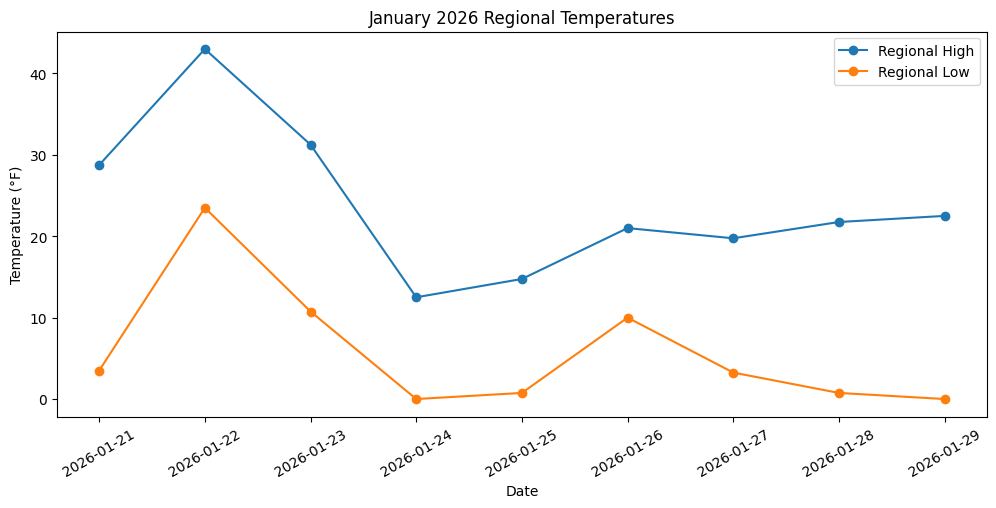

In [115]:
# Graph regional average high and low temperatures

plots.figure(figsize=(12, 5))

plots.plot(jan_weather_data["Date"], jan_weather_data["Regional High"],
           marker="o", label="Regional High")

plots.plot(jan_weather_data["Date"], jan_weather_data["Regional Low"],
           marker="o", label="Regional Low")

plots.title("January 2026 Regional Temperatures")
plots.xlabel("Date")
plots.ylabel("Temperature (°F)")
plots.xticks(rotation=30)
plots.legend()
plots.show()

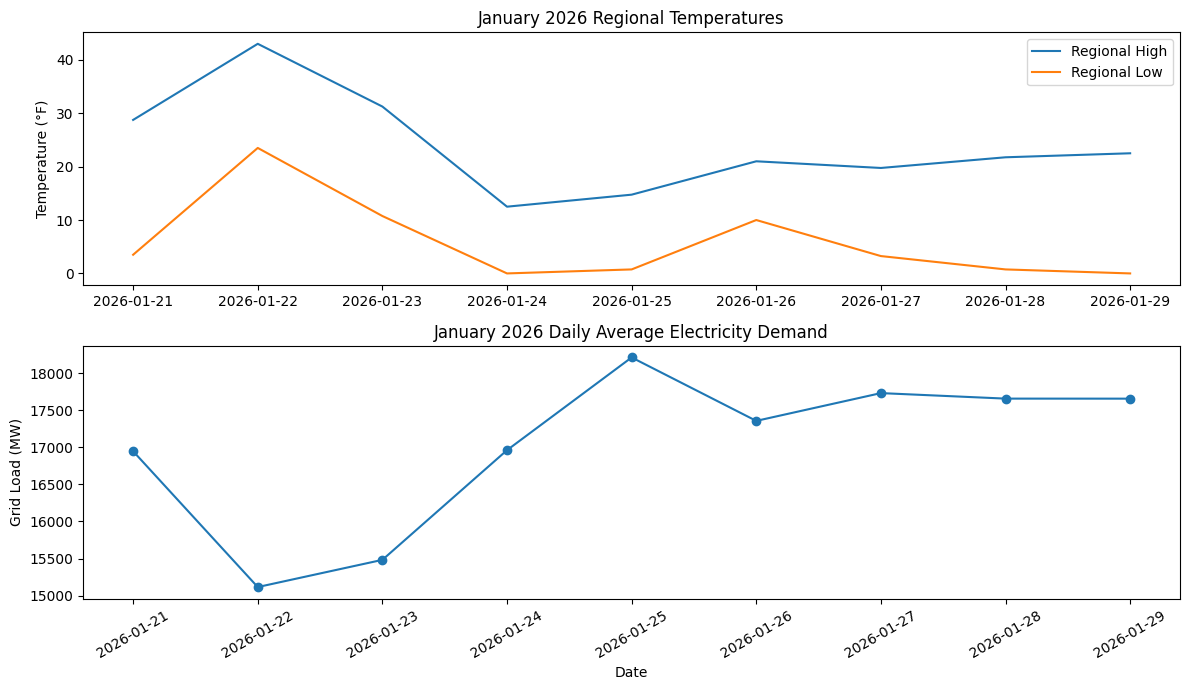

In [116]:
# Compare regional temperatures and electricity demand

plots.figure(figsize=(12, 7))

# Regional temperatures
plots.subplot(2, 1, 1)
plots.plot(jan_weather_data["Date"], jan_weather_data["Regional High"], label="Regional High")
plots.plot(jan_weather_data["Date"], jan_weather_data["Regional Low"], label="Regional Low")
plots.title("January 2026 Regional Temperatures")
plots.ylabel("Temperature (°F)")
plots.legend()

# Actual electricity demand
plots.subplot(2, 1, 2)
plots.plot(jan_daily_average.index, jan_daily_average, marker="o")
plots.title("January 2026 Daily Average Electricity Demand")
plots.xlabel("Date")
plots.ylabel("Grid Load (MW)")
plots.xticks(rotation=30)
plots.tight_layout()
plots.show()

In [117]:
# Combine January demand, forecast errors, prices, and temperatures

jan_summary = jan_daily_prices.copy()

jan_summary["Actual Demand"] = jan_daily_average.values
jan_summary["Forecast Demand"] = jan_forecast_demand

# Calculate January demand forecast error percentage
jan_summary["Forecast Error %"] = (
    (jan_summary["Actual Demand"] - jan_summary["Forecast Demand"])
    / jan_summary["Forecast Demand"]
) * 100

jan_summary["Regional High"] = jan_weather_data["Regional High"].values
jan_summary["Regional Low"] = jan_weather_data["Regional Low"].values

jan_summary = jan_summary.round(2)

jan_summary

,Day-Ahead LMP,Real-Time LMP,RT - DA Difference,Actual Demand,Forecast Demand,Forecast Error %,Regional High,Regional Low
Date,,,,,,,,
01/21/2026,134.32,148.92,14.60,16947.27,16556.25,2.36,28.75,3.50
01/22/2026,79.29,95.62,16.33,15115.71,15032.08,0.56,43.00,23.50
01/23/2026,122.96,114.22,-8.74,15482.42,15511.25,-0.19,31.25,10.75
01/24/2026,257.01,323.18,66.17,16961.69,16334.17,3.84,12.50,0.00
01/25/2026,433.96,426.28,-7.68,18212.19,17202.08,5.87,14.75,0.75
01/26/2026,436.01,365.45,-70.56,17356.68,17366.67,-0.06,21.00,10.00
01/27/2026,639.14,308.59,-330.55,17731.26,17687.92,0.25,19.75,3.25
01/28/2026,423.31,224.89,-198.42,17656.99,17622.92,0.19,21.75,0.75
01/29/2026,346.81,250.32,-96.49,17656.45,17524.17,0.75,22.50,0.00


#Case Study #2 Findings – January 2026 Winter Storm

The January 23-27, 2026 Major winter storm and associated period of extreme cold in New England was associated with notable changes in ISO-NE’s electricity demand, demand forecast accuracy, LMP pricing, and day-ahead LMP pricing. The main snowfall occurred January 25–26, with January 21–24 representing the pre-storm period and January 27–29 representing the post-storm period.

Electricity demand increased heavily as temperatures dropped ahead of the main snowfall. Average system demand rose from 15,482 MW on January 23 to 16,962 MW on January 24, before reaching 18,212 MW on January 25, the highest daily average during the observation period. Demand remained high following the storm, averaging approximately 17,656–17,731 MW from January 27–29.

Demand forecast accuracy deteriorated during the onset of extreme cold and snowfall and rebounded shortly after. Actual demand exceeded the previous-day forecast by 3.84% on January 24 and 5.87% on January 25, the largest under forecast during the observation period. By January 26, actual demand was just 0.06% below forecast, suggesting that forecast accuracy improved despite continued winter conditions.

Day-Ahead wholesale electricity prices increased significantly leading into the main snowfall period. ISO-NE Internal Hub Day-Ahead prices rose from 122.96 USD/MWh on January 23 to 257.01 USD/MWh on January 24 and 433.96 USD/MWh on January 25. Prices remained elevated after the main snowfall, reaching 639.14 USD/MWh on January 27, the highest daily Day-Ahead average during the observation period.

Real-Time prices followed a different pattern. Real-Time prices rose from 114.22 USD/MWh on January 23 to 323.18 USD/MWh on January 24, peaking at 426.28 USD/MWh on January 25, the first day of the main snowfall. Real-Time prices then declined to 365.45 USD/MWh on January 26 and 308.59 USD/MWh on January 27. On January 27, Real-Time prices were 330.55 USD/MWh below Day-Ahead price forecasts, which was the largest daily difference between the two markets during the observation period.

Regional temperatures were extremely cold leading into and during the storm. The average regional high dropped from 31.3°F on January 23 to 12.5°F on January 24, with a regional low of 0°F. Regional highs remained below 23°F throughout January 25–29, indicating that the cold weather persisted well after the main snowfall. The timing of these changes suggests that electricity demand and Real-Time prices responded most to the onset of extreme cold and the main snowfall period. However, Day-Ahead prices reached their highest level on January 27, after the main snowfall, despite relatively accurate demand forecasts.

Initial findings from this case suggest that the electricity market impacts of major winter storms can extend beyond the period of active snowfall. In this case, the combination of prolonged cold conditions, elevated demand, and notable differences between Day-Ahead and Real-Time prices highlights that the wholesale electricity market behaves in very complex ways during extreme winter weather. While temperature and snowfall appear associated with these changes, this case study alone cannot establish causation. Fuel prices, generation availability, transmission constraints, imports, and other market conditions may also have influenced prices.

# Case Study #3 February 11–14, 2024: Northeastern U.S. Winter Storm Forecasting Failure

### Storm Overview

Case Study #3 follows what was initially predicted to be a major winter storm for New England and a potential atmospheric trigger for a large-scale pattern change across North America.

Approximately 48 hours before the anticipated storm, much of the forecast guidance suggested that a major winter storm could affect the region, potentially producing 12–24 inches of snowfall, with locally higher amounts across portions of southern New England.

However, within 24 hours of the expected event, forecast models began trending significantly weaker with the southern-stream energy and more progressive with the northern-stream energy. This shift favored a farther south, more elongated, and weaker storm system.

Although portions of far southern New England still experienced significant snowfall, the much-anticipated MECS did not materialize as originally expected across the broader region.

The weaker storm evolution also meant that the system did not produce the anticipated scale of cold-air, or help establish the colder, stormier weather pattern that some earlier forecasts had suggested for the eastern United States. This resulted in a significant snowfall forecast bust and a departure from earlier temperature and atmospheric pattern expectations.

### Objective

This case study examines how ISO-NE electricity demand and wholesale electricity prices behaved during a period when a MECS was expected to bring major impacts to New England, but weather forecasts changed dramatically shortly before the storm's expected arrival.

Unlike the previous two case studies, which examined major winter storms that materialized, this analysis focuses on the relationship between an anticipated winter storm, rapidly changing weather forecasts, and actual electricity market outcomes.

### Observation Period: February 8–17, 2024

This observation window includes the days leading up to the anticipated storm, the primary expected snowfall date of February 13, and several days following the event.

The objective is to determine whether electricity demand and wholesale prices changed in anticipation of the storm, whether Day-Ahead and Real-Time prices diverged as weather forecasts evolved, and how actual market conditions compared with expectations.

Because wholesale electricity prices are influenced by many factors beyond weather, any observed relationships will be treated as associations rather than causation.


In [118]:
#Same process as Case Studies #1-2. Find the actual electricity demand for the forecast period
#Choose the three day reliability region demand forecast & hourly real time system demand Feb 9-16


# Case Study #3 - February 2024 Actual Demand

feb24_load = pd.read_csv(
    project_folder + "rt_hourlysysload_20240209_20240216.csv",
    skiprows=6,
    header=None,
    names=["Record Type", "Date", "Hour Ending", "Total Load"]
)

feb24_load = feb24_load[feb24_load["Record Type"] == "D"].copy()

feb24_load.head()


,Record Type,Date,Hour Ending,Total Load
0,D,02/09/2024,1.0,12281.45
1,D,02/09/2024,2.0,12087.19
2,D,02/09/2024,3.0,12181.02
3,D,02/09/2024,4.0,12225.78
4,D,02/09/2024,5.0,12543.18


In [119]:
#Actual demand data is by hourly. I need to seperate the data by day and find the average for each day for daily average actual demand


# Calculate daily average electricity demand

feb24_daily_average = feb24_load.groupby("Date")["Total Load"].mean()

feb24_daily_average = feb24_daily_average.round(2)

feb24_daily_average


,Total Load
Date,
02/09/2024,13373.69
02/10/2024,11824.85
02/11/2024,11943.40
02/12/2024,12904.45
02/13/2024,14323.56
02/14/2024,14279.66
02/15/2024,14212.71
02/16/2024,13910.71


In [120]:
#Above cell calculated average. I will calculate the peak and min demand for each day to see what day had the largest spike since avg's can filter that out


# Calculate daily peak electricity demand

feb24_peak_load = feb24_load.groupby("Date")["Total Load"].max()

feb24_peak_load = feb24_peak_load.round(2)

feb24_peak_load


,Total Load
Date,
02/09/2024,15117.14
02/10/2024,13825.07
02/11/2024,14847.35
02/12/2024,15571.58
02/13/2024,16517.09
02/14/2024,16983.08
02/15/2024,16497.68
02/16/2024,16142.94


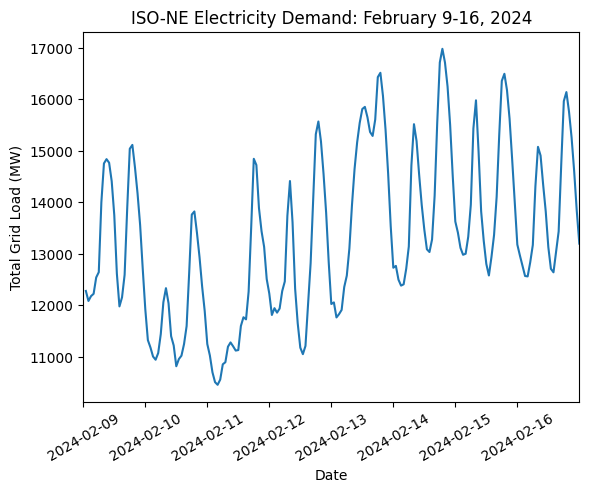

In [121]:


# Create timestamps for each hourly observation

feb24_load["Date"] = pd.to_datetime(feb24_load["Date"])

feb24_load["Timestamp"] = (
    feb24_load["Date"]
    + pd.to_timedelta(feb24_load["Hour Ending"], unit="h")
)

# Plot hourly electricity demand

plots.plot(feb24_load["Timestamp"], feb24_load["Total Load"])

plots.xticks(rotation=30)
plots.title("ISO-NE Electricity Demand: February 9-16, 2024")
plots.xlabel("Date")
plots.ylabel("Total Grid Load (MW)")

plots.xlim(pd.Timestamp("2024-02-09"), pd.Timestamp("2024-02-16 23:59"))
plots.xticks(rotation=30)

plots.show()


In [122]:
#Inspecting the data and structure



# Examine February 9, 2024 demand forecast

feb24_forecast_sample = pd.read_csv(
    project_folder + "threedayreliabilityregionloadforecastreport_20240209.csv",
    skiprows=4
)

feb24_forecast_sample.head(12)



,H,Forecast Date,Hour,Reliability Region,MW,%,Published Date
0,H,Date,HE,String,Number,Number,Date
1,D,02/09/2024,01,.Z.CONNECTICUT,2721.472,23.063,02/08/2024 09:09:01
2,D,02/09/2024,01,.Z.CONNECTICUT,2713.512,23.094,02/08/2024 04:04:34
3,D,02/09/2024,01,.Z.CONNECTICUT,2727.946,23.04,02/07/2024 14:36:41
4,D,02/09/2024,01,.Z.CONNECTICUT,2727.946,23.04,02/07/2024 09:12:53
5,D,02/09/2024,01,.Z.CONNECTICUT,2694.563,23.011,02/07/2024 03:58:39
6,D,02/09/2024,01,.Z.MAINE,1203.250,10.197,02/08/2024 09:09:01
7,D,02/09/2024,01,.Z.MAINE,1195.919,10.178,02/08/2024 04:04:34
8,D,02/09/2024,01,.Z.MAINE,1200.813,10.142,02/07/2024 14:36:41
9,D,02/09/2024,01,.Z.MAINE,1200.813,10.142,02/07/2024 09:12:53


In [123]:
#Cleaning the data: Keep only actual forecast records, convert forecast demand into numerical values, make dates into time stamps,


feb24_forecast_sample = feb24_forecast_sample[
    feb24_forecast_sample["H"] == "D"
].copy()

feb24_forecast_sample["MW"] = pd.to_numeric(
    feb24_forecast_sample["MW"]
)

feb24_forecast_sample["Published Date"] = pd.to_datetime(
    feb24_forecast_sample["Published Date"]
)

feb24_forecast_sample.head()


,H,Forecast Date,Hour,Reliability Region,MW,%,Published Date
1,D,02/09/2024,01,.Z.CONNECTICUT,2721.472,23.063,2024-02-08 09:09:01
2,D,02/09/2024,01,.Z.CONNECTICUT,2713.512,23.094,2024-02-08 04:04:34
3,D,02/09/2024,01,.Z.CONNECTICUT,2727.946,23.04,2024-02-07 14:36:41
4,D,02/09/2024,01,.Z.CONNECTICUT,2727.946,23.04,2024-02-07 09:12:53
5,D,02/09/2024,01,.Z.CONNECTICUT,2694.563,23.011,2024-02-07 03:58:39


In [124]:

# Load all February 9-16 forecast files

feb24_forecasts = pd.DataFrame()

for day in range(9, 17):
    filename = f"threedayreliabilityregionloadforecastreport_202402{day:02d}.csv"

    daily_file = pd.read_csv(
        project_folder + filename,
        skiprows=4
    )

    daily_file = daily_file[daily_file["H"] == "D"].copy()

    feb24_forecasts = pd.concat(
        [feb24_forecasts, daily_file],
        ignore_index=True
    )

print("Total forecast rows:", len(feb24_forecasts))

feb24_forecasts.head()


Total forecast rows: 10056


,H,Forecast Date,Hour,Reliability Region,MW,%,Published Date
0,D,02/09/2024,01,.Z.CONNECTICUT,2721.472,23.063,02/08/2024 09:09:01
1,D,02/09/2024,01,.Z.CONNECTICUT,2713.512,23.094,02/08/2024 04:04:34
2,D,02/09/2024,01,.Z.CONNECTICUT,2727.946,23.04,02/07/2024 14:36:41
3,D,02/09/2024,01,.Z.CONNECTICUT,2727.946,23.04,02/07/2024 09:12:53
4,D,02/09/2024,01,.Z.CONNECTICUT,2694.563,23.011,02/07/2024 03:58:39


In [125]:
#For forecasted demand we use the latest time stamp from the day before, this ensures that real time data is not included in the analysis
#for Feb 9th, this is Feb 8th at 9:09:11 AM


# Convert forecast dates and demand values

feb24_forecasts["Forecast Date"] = pd.to_datetime(
    feb24_forecasts["Forecast Date"]
)

feb24_forecasts["Published Date"] = pd.to_datetime(
    feb24_forecasts["Published Date"]
)

feb24_forecasts["MW"] = pd.to_numeric(
    feb24_forecasts["MW"]
)

# Keep forecasts published one day before the target date
feb24_previous_day = feb24_forecasts[
    feb24_forecasts["Published Date"].dt.normalize()
    == feb24_forecasts["Forecast Date"] - pd.Timedelta(days=1)
].copy()

# Find the latest publication for each forecast date
latest_publications = feb24_previous_day.groupby(
    "Forecast Date"
)["Published Date"].max()

latest_publications



,Published Date
Forecast Date,
2024-02-09,2024-02-08 09:09:01
2024-02-10,2024-02-09 09:08:12
2024-02-11,2024-02-10 09:10:09
2024-02-12,2024-02-11 12:42:13
2024-02-13,2024-02-12 09:19:44
2024-02-14,2024-02-13 09:17:42
2024-02-15,2024-02-14 09:16:17
2024-02-16,2024-02-15 10:03:10


In [126]:

# Keep the latest previous-day forecast for each date

feb24_selected_forecasts = feb24_previous_day[
    feb24_previous_day["Published Date"]
    == feb24_previous_day["Forecast Date"].map(latest_publications)
].copy()

# Check the number of records for each day
feb24_selected_forecasts.groupby("Forecast Date").size()


,0
Forecast Date,
2024-02-09,192
2024-02-10,192
2024-02-11,192
2024-02-12,192
2024-02-13,192
2024-02-14,192
2024-02-15,192
2024-02-16,192


In [127]:

# Combine the eight regional forecasts for each hour
feb24_hourly_forecast = feb24_selected_forecasts.groupby(
    ["Forecast Date", "Hour"]
)["MW"].sum()

# Calculate average forecast demand for each day
feb24_daily_forecast = feb24_hourly_forecast.groupby(
    "Forecast Date"
).mean().round(2)

feb24_daily_forecast


,MW
Forecast Date,
2024-02-09,12876.67
2024-02-10,11852.50
2024-02-11,11654.58
2024-02-12,12450.83
2024-02-13,14526.25
2024-02-14,14867.92
2024-02-15,14165.00
2024-02-16,13638.75


In [128]:

# Compare actual demand with previous-day forecasts

# Convert actual demand dates to datetime
feb24_daily_average.index = pd.to_datetime(
    feb24_daily_average.index
)

# Combine actual and forecast demand
feb24_demand_comparison = pd.DataFrame({
    "Actual Demand": feb24_daily_average,
    "Forecast Demand": feb24_daily_forecast
})

# Calculate forecast error percentage
feb24_demand_comparison["Forecast Error %"] = (
    (feb24_demand_comparison["Actual Demand"]
     - feb24_demand_comparison["Forecast Demand"])
    / feb24_demand_comparison["Forecast Demand"]
    * 100
)

feb24_demand_comparison.round(2)


,Actual Demand,Forecast Demand,Forecast Error %
2024-02-09,13373.69,12876.67,3.86
2024-02-10,11824.85,11852.50,-0.23
2024-02-11,11943.40,11654.58,2.48
2024-02-12,12904.45,12450.83,3.64
2024-02-13,14323.56,14526.25,-1.40
2024-02-14,14279.66,14867.92,-3.96
2024-02-15,14212.71,14165.00,0.34
2024-02-16,13910.71,13638.75,1.99


In [129]:
#I compared avg demand vs peak, now I am checking avg forecast peak demand vs actual peak demand


# Calculate the highest forecasted hourly demand each day

feb24_peak_forecast = feb24_hourly_forecast.groupby(
    "Forecast Date"
).max().round(2)

feb24_peak_forecast.name = "Forecast Peak Demand"

feb24_peak_forecast



,Forecast Peak Demand
Forecast Date,
2024-02-09,15050.0
2024-02-10,14000.0
2024-02-11,14750.0
2024-02-12,15530.0
2024-02-13,17010.0
2024-02-14,17500.0
2024-02-15,16700.0
2024-02-16,16400.0


In [130]:

# Compare actual and forecast peak demand

feb24_peak_load.index = pd.to_datetime(
    feb24_peak_load.index
)

feb24_peak_comparison = pd.DataFrame({
    "Actual Peak Demand": feb24_peak_load,
    "Forecast Peak Demand": feb24_peak_forecast
})

feb24_peak_comparison["Peak Forecast Error %"] = (
    (feb24_peak_comparison["Actual Peak Demand"]
     - feb24_peak_comparison["Forecast Peak Demand"])
    / feb24_peak_comparison["Forecast Peak Demand"]
    * 100
)

feb24_peak_comparison.round(2)


,Actual Peak Demand,Forecast Peak Demand,Peak Forecast Error %
2024-02-09,15117.14,15050.0,0.45
2024-02-10,13825.07,14000.0,-1.25
2024-02-11,14847.35,14750.0,0.66
2024-02-12,15571.58,15530.0,0.27
2024-02-13,16517.09,17010.0,-2.90
2024-02-14,16983.08,17500.0,-2.95
2024-02-15,16497.68,16700.0,-1.21
2024-02-16,16142.94,16400.0,-1.57


In [131]:
#Weather data (highs and Lows) for observation period. Manually implemented from NOAA

feb24_weather = pd.DataFrame({
    "Date": pd.date_range("2024-02-09", "2024-02-16"),

    "Boston High": [48, 60, 50, 45, 38, 35, 39, 39],
    "Boston Low": [30, 35, 39, 34, 32, 26, 25, 29],

    "Hartford High": [53, 62, 47, 46, 36, 33, 37, 39],
    "Hartford Low": [32, 32, 29, 23, 22, 25, 20, 26],

    "Concord High": [46, 60, 50, 47, 35, 29, 36, 35],
    "Concord Low": [22, 24, 26, 21, 22, 20, 19, 19],

    "Portland High": [40, 54, 51, 43, 36, 29, 38, 33],
    "Portland Low": [22, 28, 29, 23, 25, 20, 19, 20]
})

feb24_weather


,Date,Boston High,Boston Low,Hartford High,Hartford Low,Concord High,Concord Low,Portland High,Portland Low
0,2024-02-09,48,30,53,32,46,22,40,22
1,2024-02-10,60,35,62,32,60,24,54,28
2,2024-02-11,50,39,47,29,50,26,51,29
3,2024-02-12,45,34,46,23,47,21,43,23
4,2024-02-13,38,32,36,22,35,22,36,25
5,2024-02-14,35,26,33,25,29,20,29,20
6,2024-02-15,39,25,37,20,36,19,38,19
7,2024-02-16,39,29,39,26,35,19,33,20


In [132]:
#Find the regional high and low buy avging equally the data from all four airports.

feb24_weather["Regional High"] = feb24_weather[
    ["Boston High", "Hartford High", "Concord High", "Portland High"]
].mean(axis=1).round(2)

feb24_weather["Regional Low"] = feb24_weather[
    ["Boston Low", "Hartford Low", "Concord Low", "Portland Low"]
].mean(axis=1).round(2)

feb24_weather[["Date", "Regional High", "Regional Low"]]


,Date,Regional High,Regional Low
0,2024-02-09,46.75,26.50
1,2024-02-10,59.00,29.75
2,2024-02-11,49.50,30.75
3,2024-02-12,45.25,25.25
4,2024-02-13,36.25,25.25
5,2024-02-14,31.50,22.75
6,2024-02-15,37.50,20.75
7,2024-02-16,36.50,23.50


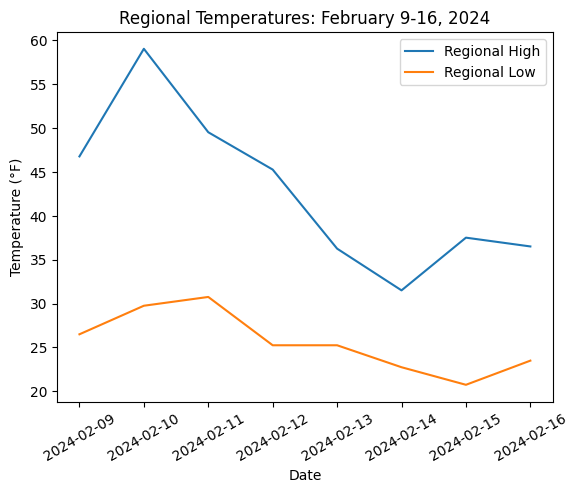

In [133]:
#Graph Regional Temps

plots.plot(feb24_weather["Date"], feb24_weather["Regional High"], label="Regional High")
plots.plot(feb24_weather["Date"], feb24_weather["Regional Low"], label="Regional Low")

plots.title("Regional Temperatures: February 9-16, 2024")
plots.xlabel("Date")
plots.ylabel("Temperature (°F)")
plots.xticks(rotation=30)
plots.legend()
plots.show()


In [134]:
#Uploading day ahead and real time LMP from internal hub location.

feb24_prices = pd.read_csv(
    project_folder + "da_rt_lmp_4000_20240209_20240216.csv",
    skiprows=6,
    header=None
)

feb24_prices.head()


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,H,Date,Hour Ending,Location ID,Location Name,Location Type,Locational Marginal Price,Energy Component,Congestion Component,Marginal Loss Component,Locational Marginal Price,Energy Component,Congestion Component,Marginal Loss Component
1,H,Date,HE,String,String,String,Number,Number,Number,Number,Number,Number,Number,Number
2,D,02/09/2024,01,4000,.H.INTERNAL_HUB,HUB,25.12,25.08,0.0,0.04,20.93,20.86,0.0,0.07
3,D,02/09/2024,02,4000,.H.INTERNAL_HUB,HUB,24.5,24.44,0.0,0.06,19.59,19.52,0.0,0.07
4,D,02/09/2024,03,4000,.H.INTERNAL_HUB,HUB,23.03,22.97,0.0,0.06,20.28,20.22,0.0,0.06


In [135]:
#Reformat the table and and identify pricing data as numerical.
feb24_prices.columns = [
    "Record Type", "Date", "Hour Ending",
    "Location ID", "Location Name", "Location Type",
    "DA LMP", "DA Energy", "DA Congestion", "DA Loss",
    "RT LMP", "RT Energy", "RT Congestion", "RT Loss"
]

feb24_prices = feb24_prices[
    feb24_prices["Record Type"] == "D"
].copy()

feb24_prices["Date"] = pd.to_datetime(feb24_prices["Date"])

feb24_prices["DA LMP"] = pd.to_numeric(feb24_prices["DA LMP"])
feb24_prices["RT LMP"] = pd.to_numeric(feb24_prices["RT LMP"])

feb24_prices.head()


,Record Type,Date,Hour Ending,Location ID,Location Name,Location Type,DA LMP,DA Energy,DA Congestion,DA Loss,RT LMP,RT Energy,RT Congestion,RT Loss
2,D,2024-02-09,01,4000,.H.INTERNAL_HUB,HUB,25.12,25.08,0.0,0.04,20.93,20.86,0.0,0.07
3,D,2024-02-09,02,4000,.H.INTERNAL_HUB,HUB,24.50,24.44,0.0,0.06,19.59,19.52,0.0,0.07
4,D,2024-02-09,03,4000,.H.INTERNAL_HUB,HUB,23.03,22.97,0.0,0.06,20.28,20.22,0.0,0.06
5,D,2024-02-09,04,4000,.H.INTERNAL_HUB,HUB,22.90,22.84,0.0,0.06,20.21,20.14,0.0,0.07
6,D,2024-02-09,05,4000,.H.INTERNAL_HUB,HUB,24.48,24.42,0.0,0.06,20.01,19.94,0.0,0.07


In [136]:
#calculate daily average DA and RT LMP



# Calculate daily average Day-Ahead and Real-Time LMP

feb24_daily_prices = feb24_prices.groupby("Date")[
    ["DA LMP", "RT LMP"]
].mean()

feb24_daily_prices["RT - DA"] = (
    feb24_daily_prices["RT LMP"] - feb24_daily_prices["DA LMP"]
)

feb24_daily_prices.round(2)


,DA LMP,RT LMP,RT - DA
Date,,,
2024-02-09,28.38,23.15,-5.23
2024-02-10,22.66,22.67,0.01
2024-02-11,23.67,26.78,3.11
2024-02-12,29.06,25.43,-3.62
2024-02-13,42.11,29.42,-12.69
2024-02-14,46.41,30.69,-15.71
2024-02-15,40.44,32.66,-7.77
2024-02-16,30.81,28.96,-1.85


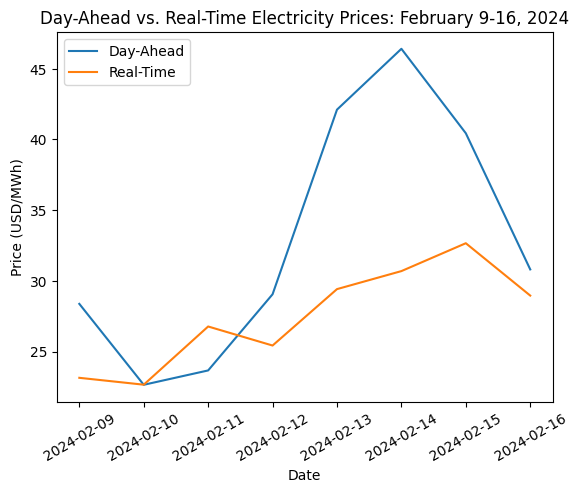

In [137]:

plots.plot(feb24_daily_prices.index, feb24_daily_prices["DA LMP"], label="Day-Ahead")
plots.plot(feb24_daily_prices.index, feb24_daily_prices["RT LMP"], label="Real-Time")

plots.title("Day-Ahead vs. Real-Time Electricity Prices: February 9-16, 2024")
plots.xlabel("Date")
plots.ylabel("Price (USD/MWh)")
plots.xticks(rotation=30)

plots.legend()
plots.show()


In [138]:
#Bring all components together


feb24_summary = feb24_demand_comparison.copy()

feb24_summary["Regional High"] = feb24_weather.set_index("Date")["Regional High"]
feb24_summary["Regional Low"] = feb24_weather.set_index("Date")["Regional Low"]

feb24_summary["Day-Ahead Price"] = feb24_daily_prices["DA LMP"]
feb24_summary["Real-Time Price"] = feb24_daily_prices["RT LMP"]
feb24_summary["RT - DA"] = feb24_daily_prices["RT - DA"]

feb24_summary.round(2)


,Actual Demand,Forecast Demand,Forecast Error %,Regional High,Regional Low,Day-Ahead Price,Real-Time Price,RT - DA
2024-02-09,13373.69,12876.67,3.86,46.75,26.50,28.38,23.15,-5.23
2024-02-10,11824.85,11852.50,-0.23,59.00,29.75,22.66,22.67,0.01
2024-02-11,11943.40,11654.58,2.48,49.50,30.75,23.67,26.78,3.11
2024-02-12,12904.45,12450.83,3.64,45.25,25.25,29.06,25.43,-3.62
2024-02-13,14323.56,14526.25,-1.40,36.25,25.25,42.11,29.42,-12.69
2024-02-14,14279.66,14867.92,-3.96,31.50,22.75,46.41,30.69,-15.71
2024-02-15,14212.71,14165.00,0.34,37.50,20.75,40.44,32.66,-7.77
2024-02-16,13910.71,13638.75,1.99,36.50,23.50,30.81,28.96,-1.85


#Case Study #3 Findings: February 11–14, 2024: Northeastern U.S. Winter Storm Forecasting Failure

The February 11–14, 2024 winter storm brings to light an interesting example of how a forecasting miss, with dramatically changing real-time weather expectations, can coincide with differences between forecasted electricity demand and actual wholesale electricity pricing in ISO-NE.

Regional temperatures fell substantially during the observation period. The average high temperature across Boston, Hartford, Concord, and Portland decreased from 59°F on February 10 to 31.5°F on February 14. As temperatures dropped, average daily electricity demand increased from 11,825 MW on February 10 to 14,324 MW on February 13. This suggests that colder conditions likely contributed to increased electricity consumption, even without widespread heavy snowfall.

However, despite this increase in demand, actual consumption remained below ISO-NE's previous-day forecasts during the key dates. On February 13, actual demand averaged 14,324 MW, 1.40% below forecast. On February 14, actual demand averaged 14,280 MW, 3.96% below forecast. These results indicate that ISO-NE anticipated greater electricity consumption than what actually occurred on both days.

Day-Ahead electricity prices increased considerably during this period. The Internal Hub's average Day-Ahead LMP rose from 29.06 USD/MWh on February 12 to 42.11 USD/MWh on February 13, reaching 46.41 USD/MWh on February 14. Real-Time prices were significantly lower, averaging 29.42 USD/MWh on February 13 and 30.69 USD/MWh on February 14.

Consequently, Real-Time prices were 12.69 USD/MWh below Day-Ahead prices on February 13 and 15.72 USD/MWh below on February 14. February 14 represented the largest negative daily price difference during the eight-day observation period.

The combination of overestimated electricity demand and lower Real-Time prices suggests that conditions anticipated by the market differed from those ultimately experienced. While the changing storm forecast may have contributed to these differences, this analysis cannot establish a direct causal relationship. Wholesale electricity prices are also influenced by fuel costs, generation availability, transmission constraints, imports, and other market conditions.

Overall, this case study demonstrates how differences between forecasted and realized electricity market conditions can coincide with substantial Day-Ahead versus Real-Time price deltas. It also highlights why accurately forecasting electricity demand and understanding weather-related uncertainty are important in wholesale power markets. Therefore, based on this case study, it is reasonable to conclude that forecast accuracy plays an important role in anticipating market demand, while unexpected changes in conditions may contribute to differences between Day-Ahead and Real-Time electricity prices.


In [139]:
# Standardize the column headers and order for all three case studies

columns = [
    "Actual Demand", "Forecast Demand", "Forecast Error %",
    "Day-Ahead Price", "Real-Time Price", "RT - DA",
    "Regional High", "Regional Low"
]

# Standardize January's summary column names and order

jan_summary = jan_summary.rename(columns={
    "Day-Ahead LMP": "Day-Ahead Price",
    "Real-Time LMP": "Real-Time Price",
    "RT - DA Difference": "RT - DA"
})

jan_summary = jan_summary[
    ["Actual Demand", "Forecast Demand", "Forecast Error %",
     "Day-Ahead Price", "Real-Time Price", "RT - DA",
     "Regional High", "Regional Low"]
]

jan_summary.round(2)


# Calculate January's forecast demand from actual demand and forecast error
jan_summary["Forecast Demand"] = jan_summary["Actual Demand"] / (
    1 + jan_summary["Forecast Error %"] / 100
)

summary = summary[columns]
jan_summary = jan_summary[columns]
feb24_summary = feb24_summary[columns]


In [140]:
# Creating a summary table of demand forecasting error, Day-Ahead vs real time pricing, and temp
# Code below finds the existing summary tables from our three case studies

# Display the original summary tables for all three case studies

print("Case Study #1 - February 2026 Blizzard")
display(summary)

print("Case Study #2 - January 2026 Winter Storm")
display(jan_summary)

print("Case Study #3 - February 2024 Forecasting Failure")
display(feb24_summary)

Case Study #1 - February 2026 Blizzard


,Actual Demand,Forecast Demand,Forecast Error %,Day-Ahead Price,Real-Time Price,RT - DA,Regional High,Regional Low
2026-02-19,13908.865417,14027.500333,-0.845731,75.899583,58.339167,-17.560417,40.25,22.25
2026-02-20,15031.095417,14490.000417,3.734265,68.829583,59.892917,-8.936667,35.75,25.25
2026-02-21,14270.631250,13569.167000,5.169545,59.995000,61.760417,1.765417,34.50,22.50
2026-02-22,14237.104583,14025.833625,1.506299,60.246250,56.710417,-3.535833,33.75,20.75
2026-02-23,15151.423333,15470.000167,-2.059320,79.522917,69.076250,-10.446667,31.50,22.75
2026-02-24,14975.518333,15702.083542,-4.627190,79.846250,91.046250,11.200000,30.75,13.75
2026-02-25,15817.977917,15202.917125,4.045676,87.550833,89.549583,1.998750,35.25,9.25
2026-02-26,14419.171250,13893.333875,3.784818,64.455417,63.718750,-0.736667,40.50,19.00


Case Study #2 - January 2026 Winter Storm


,Actual Demand,Forecast Demand,Forecast Error %,Day-Ahead Price,Real-Time Price,RT - DA,Regional High,Regional Low
Date,,,,,,,,
01/21/2026,16947.27,16556.535756,2.36,134.32,148.92,14.60,28.75,3.50
01/22/2026,15115.71,15031.533413,0.56,79.29,95.62,16.33,43.00,23.50
01/23/2026,15482.42,15511.892596,-0.19,122.96,114.22,-8.74,31.25,10.75
01/24/2026,16961.69,16334.447227,3.84,257.01,323.18,66.17,12.50,0.00
01/25/2026,18212.19,17202.408614,5.87,433.96,426.28,-7.68,14.75,0.75
01/26/2026,17356.68,17367.100260,-0.06,436.01,365.45,-70.56,21.00,10.00
01/27/2026,17731.26,17687.042394,0.25,639.14,308.59,-330.55,19.75,3.25
01/28/2026,17656.99,17623.505340,0.19,423.31,224.89,-198.42,21.75,0.75
01/29/2026,17656.45,17525.012407,0.75,346.81,250.32,-96.49,22.50,0.00


Case Study #3 - February 2024 Forecasting Failure


,Actual Demand,Forecast Demand,Forecast Error %,Day-Ahead Price,Real-Time Price,RT - DA,Regional High,Regional Low
2024-02-09,13373.69,12876.67,3.859849,28.378750,23.151250,-5.227500,46.75,26.50
2024-02-10,11824.85,11852.50,-0.233284,22.657917,22.665833,0.007917,59.00,29.75
2024-02-11,11943.40,11654.58,2.478167,23.673333,26.779167,3.105833,49.50,30.75
2024-02-12,12904.45,12450.83,3.643291,29.056667,25.433750,-3.622917,45.25,25.25
2024-02-13,14323.56,14526.25,-1.395336,42.106667,29.420833,-12.685833,36.25,25.25
2024-02-14,14279.66,14867.92,-3.956572,46.407500,30.694583,-15.712917,31.50,22.75
2024-02-15,14212.71,14165.00,0.336816,40.438333,32.664583,-7.773750,37.50,20.75
2024-02-16,13910.71,13638.75,1.994024,30.813333,28.963750,-1.849583,36.50,23.50


In [141]:

# Combine the three winter storm summaries for comparison

storm_comparison = pd.concat([
    summary.assign(Storm="February 2026 Blizzard"),
    jan_summary.assign(Storm="January 2026 Winter Storm"),
    feb24_summary.assign(Storm="February 2024 Storm")
])

storm_comparison


,Actual Demand,Forecast Demand,Forecast Error %,Day-Ahead Price,Real-Time Price,RT - DA,Regional High,Regional Low,Storm
2026-02-19 00:00:00,13908.865417,14027.500333,-0.845731,75.899583,58.339167,-17.560417,40.25,22.25,February 2026 Blizzard
2026-02-20 00:00:00,15031.095417,14490.000417,3.734265,68.829583,59.892917,-8.936667,35.75,25.25,February 2026 Blizzard
2026-02-21 00:00:00,14270.631250,13569.167000,5.169545,59.995000,61.760417,1.765417,34.50,22.50,February 2026 Blizzard
2026-02-22 00:00:00,14237.104583,14025.833625,1.506299,60.246250,56.710417,-3.535833,33.75,20.75,February 2026 Blizzard
2026-02-23 00:00:00,15151.423333,15470.000167,-2.059320,79.522917,69.076250,-10.446667,31.50,22.75,February 2026 Blizzard
2026-02-24 00:00:00,14975.518333,15702.083542,-4.627190,79.846250,91.046250,11.200000,30.75,13.75,February 2026 Blizzard
2026-02-25 00:00:00,15817.977917,15202.917125,4.045676,87.550833,89.549583,1.998750,35.25,9.25,February 2026 Blizzard
2026-02-26 00:00:00,14419.171250,13893.333875,3.784818,64.455417,63.718750,-0.736667,40.50,19.00,February 2026 Blizzard
01/21/2026,16947.270000,16556.535756,2.360000,134.320000,148.920000,14.600000,28.75,3.50,January 2026 Winter Storm
01/22/2026,15115.710000,15031.533413,0.560000,79.290000,95.620000,16.330000,43.00,23.50,January 2026 Winter Storm


In [142]:

# Compare average demand and electricity prices across the three storms

storm_averages = storm_comparison.groupby("Storm")[
    ["Actual Demand", "Day-Ahead Price", "Real-Time Price"]
].mean()

storm_averages.round(2)


,Actual Demand,Day-Ahead Price,Real-Time Price
Storm,,,
February 2024 Storm,13346.63,32.94,27.47
February 2026 Blizzard,14726.47,72.04,68.76
January 2026 Winter Storm,17013.41,319.20,250.83


In [143]:
#code the demand forecasting error against all three storms to see which one was forecasted correctly

# Compare average absolute demand forecast errors across the three storms

storm_forecast_errors = storm_comparison.groupby("Storm")["Forecast Error %"].apply(
    lambda errors: errors.abs().mean()
)

storm_forecast_errors.round(2)


,Forecast Error %
Storm,
February 2024 Storm,2.24
February 2026 Blizzard,3.22
January 2026 Winter Storm,1.56


In [144]:

# Compare the largest daily Day-Ahead and Real-Time price differences

storm_price_gaps = storm_comparison.groupby("Storm")["RT - DA"].apply(
    lambda prices: prices.abs().max()
)

storm_price_gaps.round(2)


,RT - DA
Storm,
February 2024 Storm,15.71
February 2026 Blizzard,17.56
January 2026 Winter Storm,330.55


In [145]:

# Compare typical daily price differences using the median

storm_median_gaps = storm_comparison.groupby("Storm")["RT - DA"].apply(
    lambda prices: prices.abs().median()
)

storm_median_gaps.round(2)


,RT - DA
Storm,
February 2024 Storm,4.43
February 2026 Blizzard,6.24
January 2026 Winter Storm,66.17


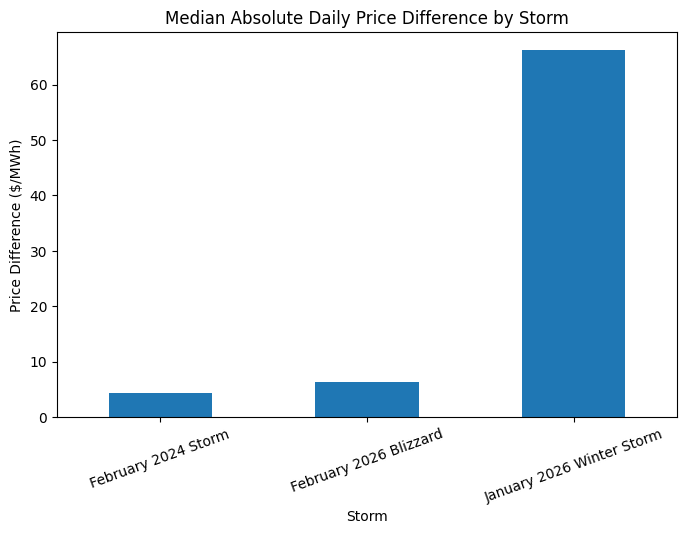

In [146]:


# Plot median absolute daily price differences across the three storms

storm_median_gaps.plot(kind="bar", figsize=(8, 5))

plots.title("Median Absolute Daily Price Difference by Storm")
plots.ylabel("Price Difference ($/MWh)")
plots.xlabel("Storm")
plots.xticks(rotation=20)
plots.show()


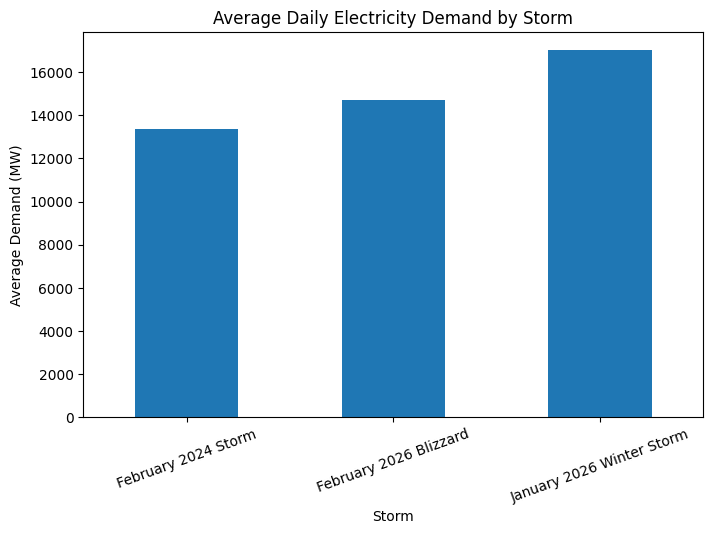

In [147]:

# Compare average electricity demand across the three storms

storm_averages["Actual Demand"].plot(kind="bar", figsize=(8, 5))

plots.title("Average Daily Electricity Demand by Storm")
plots.ylabel("Average Demand (MW)")
plots.xlabel("Storm")
plots.xticks(rotation=20)
plots.show()


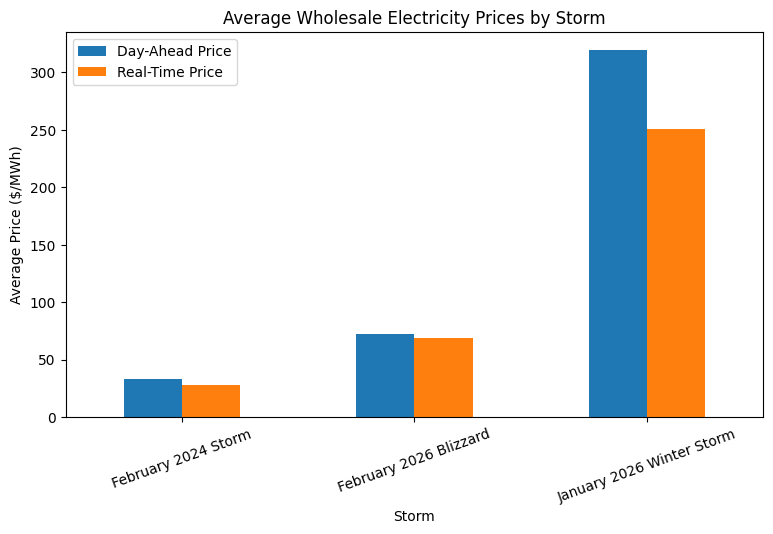

In [148]:

# Compare average Day-Ahead and Real-Time electricity prices across the three storms

storm_averages[["Day-Ahead Price", "Real-Time Price"]].plot(
    kind="bar", figsize=(9, 5)
)

plots.title("Average Wholesale Electricity Prices by Storm")
plots.ylabel("Average Price ($/MWh)")
plots.xlabel("Storm")
plots.xticks(rotation=20)
plots.legend()
plots.show()


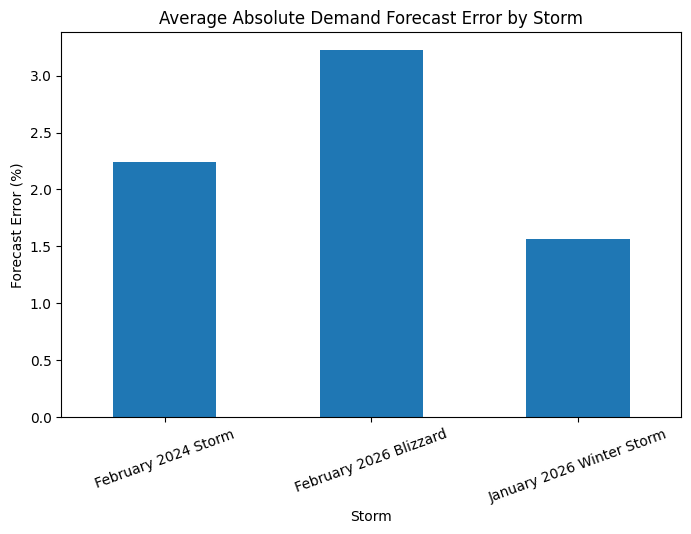

In [149]:

# Compare average absolute demand forecast errors across the three storms

storm_forecast_errors.plot(kind="bar", figsize=(8, 5))

plots.title("Average Absolute Demand Forecast Error by Storm")
plots.ylabel("Forecast Error (%)")
plots.xlabel("Storm")
plots.xticks(rotation=20)
plots.show()


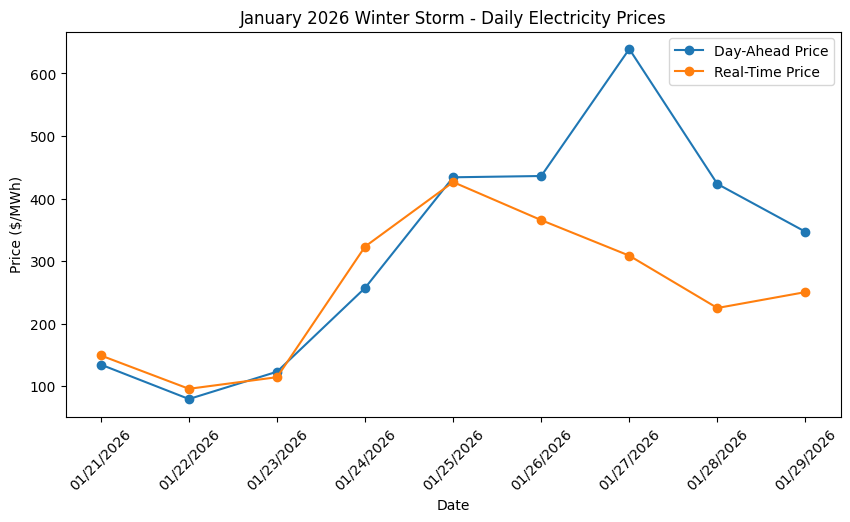

In [150]:

# Compare daily Day-Ahead and Real-Time prices during January 2026

jan_summary[["Day-Ahead Price", "Real-Time Price"]].plot(
    kind="line", marker="o", figsize=(10, 5)
)

plots.title("January 2026 Winter Storm - Daily Electricity Prices")
plots.ylabel("Price ($/MWh)")
plots.xlabel("Date")
plots.xticks(rotation=45)
plots.show()


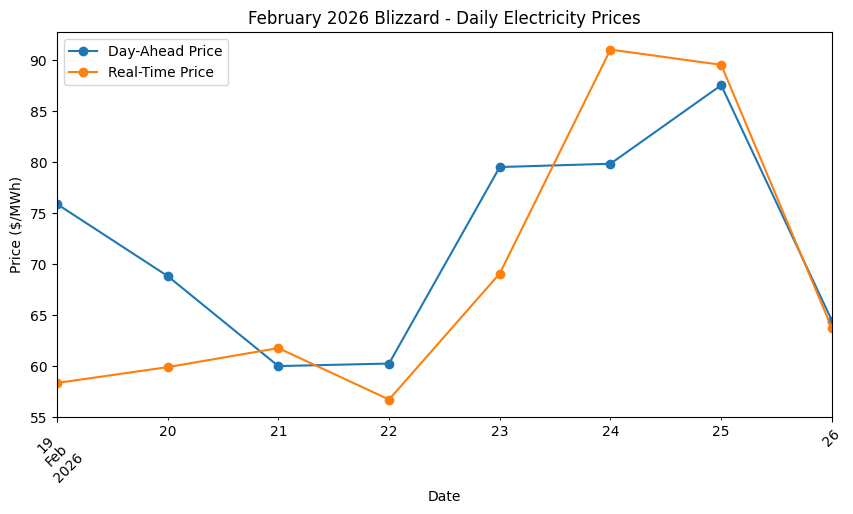

In [151]:

# Compare daily Day-Ahead and Real-Time prices during February 2026

summary[["Day-Ahead Price", "Real-Time Price"]].plot(
    kind="line", marker="o", figsize=(10, 5)
)

plots.title("February 2026 Blizzard - Daily Electricity Prices")
plots.ylabel("Price ($/MWh)")
plots.xlabel("Date")
plots.xticks(rotation=45)
plots.show()


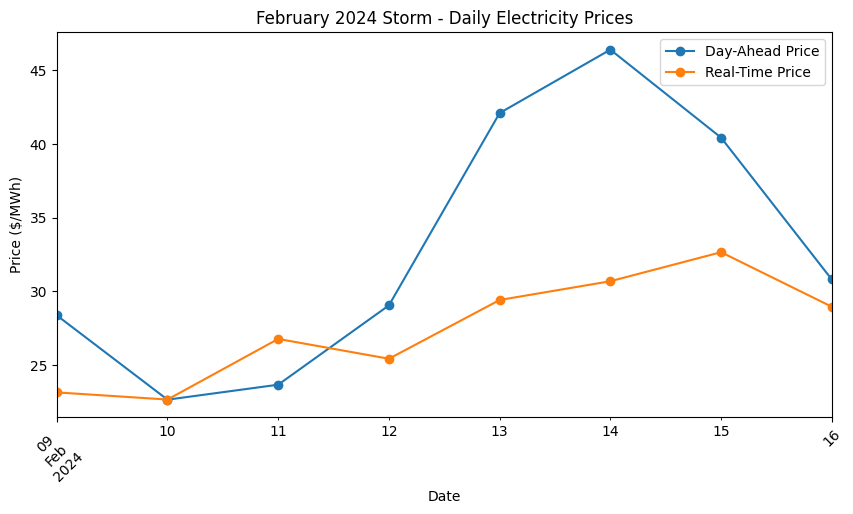

In [152]:

# Compare daily Day-Ahead and Real-Time prices during February 2024

feb24_summary[["Day-Ahead Price", "Real-Time Price"]].plot(
    kind="line", marker="o", figsize=(10, 5)
)

plots.title("February 2024 Storm - Daily Electricity Prices")
plots.ylabel("Price ($/MWh)")
plots.xlabel("Date")
plots.xticks(rotation=45)
plots.show()


In [153]:

# Compare electricity demand and prices before, during, and after the January storm

jan_periods = jan_summary.copy()

jan_periods["Period"] = (
    ["Before"] * 4 +
    ["During"] * 2 +
    ["After"] * 3
)

jan_period_comparison = jan_periods.groupby("Period")[
    ["Actual Demand", "Day-Ahead Price", "Real-Time Price"]
].mean()

jan_period_comparison.round(2)


,Actual Demand,Day-Ahead Price,Real-Time Price
Period,,,
After,17681.57,469.75,261.27
Before,16126.77,148.39,170.48
During,17784.43,434.98,395.86


In [154]:

# Compare electricity demand and prices before, during, and after the February 2026 blizzard

feb26_periods = summary.copy()

feb26_periods["Period"] = (
    ["Before"] * 3 +
    ["During"] * 3 +
    ["After"] * 2
)

feb26_period_comparison = feb26_periods.groupby("Period")[
    ["Actual Demand", "Day-Ahead Price", "Real-Time Price"]
].mean()

feb26_period_comparison.round(2)



,Actual Demand,Day-Ahead Price,Real-Time Price
Period,,,
After,15118.57,76.00,76.63
Before,14403.53,68.24,60.00
During,14788.02,73.21,72.28


In [155]:

# Compare electricity demand and prices before, during, and after the February 2024 storm

feb24_periods = feb24_summary.copy()

feb24_periods["Period"] = (
    ["Before"] * 4 +
    ["During"] * 2 +
    ["After"] * 2
)

feb24_period_comparison = feb24_periods.groupby("Period")[
    ["Actual Demand", "Day-Ahead Price", "Real-Time Price"]
].mean()

feb24_period_comparison.round(2)


,Actual Demand,Day-Ahead Price,Real-Time Price
Period,,,
After,14061.71,35.63,30.81
Before,12511.60,25.94,24.51
During,14301.61,44.26,30.06


# ISO-NE Winter Storm Analysis — Final Findings and Conclusions

This analysis focused on three major New England winter storms characterized by different meteorological conditions and market responses.

### Case Study #1: The Blizzard of February 22–23, 2026

**Observation Period: February 19–26, 2026**

The Blizzard of February 2026 was known for its rapidly deepening cyclone, which caused intense blizzard conditions, strong winds, and whiteout snowfall rates across portions of New England. While temperatures were cold, the average regional high during the observation period was approximately 31.5°F, representing relatively seasonal winter cold rather than an extreme Arctic outbreak.

From an electricity market perspective, this event experienced a smaller increase in demand compared with the other two storms. Average actual demand increased 2.7% from the pre-storm period to the storm period, while Day-Ahead electricity prices increased 7.3% and Real-Time prices increased 20.5%.

Interestingly, average demand and both electricity price measures remained elevated after the storm, with post-storm averages exceeding those recorded during the storm itself. This suggests that the market response extended beyond the period of the most intense snowfall and blizzard conditions.

### Case Study #2: The Major Northeastern Snowstorm of January 23–27, 2026

**Observation Period: January 21–29, 2026**

The Major Northeastern Snowstorm of January 2026 was characterized by an intense Arctic blast that preceded the storm, followed by an awakening subtropical jet stream providing an abundance of subtropical moisture interacting with the existing cold air mass. This combination produced a large, powerful, long-duration winter storm.

Unlike Case Study #1, this storm was not primarily characterized by blizzard conditions. Instead, it featured prolonged snowfall, high snow-to-liquid ratios, and exceptionally cold temperatures.

From an electricity market perspective, this event experienced the most significant wholesale price movements of the three case studies. Average actual demand increased 10.3% during the storm, while Day-Ahead electricity prices increased approximately 193.1% and Real-Time prices increased approximately 132.2% compared with pre-storm averages.

Another notable observation was the significant divergence between Day-Ahead and Real-Time pricing following the storm. Average Day-Ahead prices remained elevated at $469.75/MWh, while Real-Time prices declined to $261.27/MWh.

This suggests that the conditions and expectations reflected in the Day-Ahead market differed considerably from the conditions ultimately reflected in Real-Time pricing. However, the specific market factors responsible for this disparity were not independently observed here.

### Case Study #3: The Forecasting Failure of February 13–14, 2024

**Observation Period: February 9–16, 2024**

The February 2024 storm was initially forecast to become a major nor'easter, with the potential for a clean phasing of northern and southern atmospheric energy. This interaction was expected to produce intense winds, significant snowfall, and a strong cold front in the storm's wake.

In reality, the northern energy progressed more quickly and became more elongated than initially modeled, limiting its interaction with the southern energy. This resulted in a weaker phase and a storm track farther south than originally forecast.

This case study was selected to examine electricity market behavior surrounding a winter storm whose actual meteorological impacts were substantially less severe than anticipated.

Interestingly, this event experienced the largest percentage increase in electricity demand of the three case studies. Average actual demand increased 14.3% during the storm compared with the pre-storm period.

Day-Ahead electricity prices increased approximately 70.6%, while Real-Time prices increased 22.6%.

The difference between the Day-Ahead and Real-Time price increases is particularly interesting given the storm's forecasting history. It raises the possibility that changing weather expectations contributed to differences between the two markets. However, this analysis does not establish that weather forecast errors directly caused the observed price differences.

## Key Findings Across the Three Case Studies

The analysis demonstrates that winter storms can coincide with increased electricity demand and significant wholesale pricing movements in the ISO-NE power market. However, the magnitude and timing of these changes varied considerably across the three studies.

One of the most significant findings was that **the storm with the largest percentage increase in electricity demand did not experience the largest increase in wholesale electricity prices.**

The February 2024 storm experienced the largest increase in actual demand at 14.3%, followed by January 2026 at 10.3% and February 2026 at 2.7%.

However, January 2026 experienced by far the largest wholesale electricity price increases, with Day-Ahead and Real-Time prices rising approximately 193.1% and 132.2%, respectively.

This indicates that changes in electricity demand alone cannot fully explain the differences in wholesale electricity pricing observed across the three events.

Another important finding was the difference in how Day-Ahead and Real-Time prices responded to each storm.

During January 2026, Day-Ahead and Real-Time prices increased dramatically, followed by a significant disparity in the post-storm period. During February 2024, Day-Ahead prices increased substantially more than Real-Time prices. In comparison, February 2026 experienced smaller price movements, with Day-Ahead and Real-Time prices remaining relatively close throughout the observation period.

These differences highlight the importance of evaluating both markets when analyzing the impact of winter weather on wholesale electricity prices.

## Conclusion and Limitations

This study focused on electricity demand and wholesale pricing before, during, and after three specified winter weather events. Historical temperature data from NOAA was used to provide meteorological context, while demand forecasts, actual demand, Day-Ahead prices, and Real-Time prices were sourced directly from ISO-NE's data archives and analyzed to identify changes in electricity market behavior.

It is important to note that factors such as fuel availability, generation constraints, transmission conditions, and market expectations may help explain the differences observed across the three case studies, although they were not independently evaluated in this project. Incorporating additional data on these variables, along with a larger sample of winter weather events, could support a more comprehensive statistical analysis of the relationship between extreme winter weather, electricity demand, and wholesale electricity pricing. However, the purpose of this project was to identify and compare observable market trends surrounding three distinct winter weather events, rather than develop a statistical model to explain or predict wholesale electricity prices.

Additionally, the analysis used daily averages of hourly electricity market data. While this approach helped identify general trends, it may not fully capture short periods of extreme demand or price volatility. Furthermore, using ISO-NE system-wide demand and Internal Hub electricity prices may overlook differences in market conditions across individual locations within New England.

Because this analysis covers only three storms and uses descriptive comparisons rather than a controlled statistical model, the results should not be interpreted as proving that the storms directly caused the observed changes.

Overall, the project highlights the importance of analyzing both electricity demand and market pricing when evaluating the impact of extreme weather on the ISO-NE power grid. The differences observed across the three case studies suggest that the relationship between winter weather, electricity demand, and wholesale prices is complex and cannot be explained by demand changes alone.
